# MLOps – Data Lab: NYC Yellow Taxi (STUDENT version)

**Goal.** Build a *reliable data flow* around a real dataset: ingest → explore → validate → clean → split → version → monitor.
We predict **trip duration (minutes)** at the moment a ride starts. The model is secondary; the data discipline is the point.

**How this notebook works**
- 🤔 **Think first** – questions to answer *before* you code. Write answers in the ✍️ cell. EDA is about asking good questions.
- 🛠 **TODO cells** – you write the code. Hints are in comments.
- ✅ **Self-check cells** – run them to see whether your work is on the right track.
- Do **not** skip the written answers: they are graded.

**Data.** NYC Taxi & Limousine Commission (TLC) yellow taxi trip records, one Parquet file per month (downloaded automatically, ~50 MB each).
Data dictionary: https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf – **open it now**.

## Step 0 – Frame the problem (before touching data)

### 🤔 Think first

1. What is **one row** (the grain) of this dataset?
2. We want to predict trip duration **when the ride starts**. What is the target, and *at what moment* does the model make its prediction?
3. Look at the data dictionary. Which columns are **known at prediction time** and which are only known **after** the trip? (This decides which features are allowed.)
4. Who would use this prediction, and what would a *bad* prediction cost?

### ✍️ Your answers

- **Q1:** What is **one row** (the grain) of this dataset?

  **Answer:** One row is **one completed yellow taxi trip**, as recorded by the taximeter. It covers a single ride from the moment the meter is engaged (`tpep_pickup_datetime`, in zone `PULocationID`) to the moment it is disengaged

  
- **Q2**:

    **Target:** the trip duration, computed as `tpep_dropoff_datetime - tpep_pickup_datetime` (in minutes).

   **Prediction moment:** at the start of the ride, when the meter is engaged (`tpep_pickup_datetime`). Only information available at that time can be used as features.

- **Q3** : 

    **Known at prediction time (allowed features):**
   - `tpep_pickup_datetime` (hour, weekday, month)
   - `PULocationID`
   - `VendorID`
   - `passenger_count`
   - `DOLocationID` (only if the destination is stated at pickup)

   **Known only after the trip (excluded to avoid data leakage):**
   - `tpep_dropoff_datetime` (the target itself)
   - `trip_distance`
   - `RatecodeID` (final rate code in effect at the end of the trip)
   - `store_and_fwd_flag`
   - `payment_type`
   - `fare_amount`, `extra`, `mta_tax`, `tolls_amount`, `improvement_surcharge`, `congestion_surcharge`, `airport_fee`, `cbd_congestion_fee`, `total_amount`
   - `tip_amount`
- **Q4:** 

    **Users:** passengers (to plan their arrival time, e.g. airport or appointment), drivers and fleet operators (to choose rides and plan the next one), and dispatch apps or the TLC (to allocate taxis and estimate waiting times).

   **Cost of a bad prediction:** underestimating the duration is the most costly error, because passengers arrive late or miss a flight or meeting, and drivers plan their next ride badly. Overestimating is less harmful but still wastes time and revenue (passengers leave too early or choose another service, taxis are blocked longer than needed). Errors matter most on long trips (airport, rush hour), where the gap in minutes is largest. For this reason, the model should be evaluated with an error measured in minutes (such as MAE), with extra attention to underestimation and to long trips.

## Setup and helper functions

Run these cells as they are. Read the helpers – they are used throughout the lab.

In [2]:
import json, hashlib, urllib.request, warnings, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyarrow.parquet as pq
from scipy import stats
import sklearn, joblib
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
warnings.filterwarnings("ignore"); pd.set_option("display.max_columns", 40); pd.set_option("display.width", 140)

RAW, PROC, ART = Path("data/raw"), Path("data/processed"), Path("artifacts")
for p in (RAW, PROC, ART): p.mkdir(parents=True, exist_ok=True)
SEED, SAMPLE_N = 42, 200_000          # we sample 200k rows per month to keep the lab fast
REF_MONTH = "2024-01"                 # reference month = data version v1
BASE_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{ym}.parquet"
KEEP = ["VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count", "trip_distance", "RatecodeID",
        "PULocationID", "DOLocationID", "payment_type", "fare_amount", "tip_amount", "total_amount"]
ROWS_IN_FILE = {}

def month_bounds(ym):
    start = pd.Timestamp(ym + "-01"); return start, start + pd.offsets.MonthBegin(1)

def download_month(ym):
    path = RAW / f"yellow_tripdata_{ym}.parquet"
    if not path.exists():
        print(f"downloading {ym} ..."); urllib.request.urlretrieve(BASE_URL.format(ym=ym), path)
    return path

def load_month(ym, n=SAMPLE_N):
    path = download_month(ym); names = pq.ParquetFile(path).schema.names
    df = pd.read_parquet(path, columns=[c for c in KEEP if c in names])
    ROWS_IN_FILE[ym] = len(df)
    if n and len(df) > n: df = df.sample(n, random_state=SEED)
    return df.sort_values("tpep_pickup_datetime").reset_index(drop=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()
print("setup ok | pandas", pd.__version__, "| sklearn", sklearn.__version__)

setup ok | pandas 3.0.0 | sklearn 1.8.0


## Step 1 – Ingest raw data

The downloaded Parquet file is our **raw layer**. We never edit it. Because a month has ~3 million rows we work with a reproducible random sample (`SEED`) of 200k rows.

### 🤔 Think first

1. How many rows are in the file vs in our sample? Why is it important that the sample is seeded?
2. Which columns are numeric, datetime, identifiers? Does any dtype look suspicious (e.g. an integer stored as float)?
3. Why keep the original Parquet file untouched instead of saving a cleaned version over it?

In [3]:
df = load_month(REF_MONTH)
print(f"file: {ROWS_IN_FILE[REF_MONTH]:,} rows | sample: {len(df):,} rows "
      f"({len(df)/ROWS_IN_FILE[REF_MONTH]:.1%})")

file: 2,964,624 rows | sample: 200,000 rows (6.7%)


### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:**  

   **Rows:** the raw file contains **2,964,624** rows, while our working sample contains **200,000** rows (6.7% of the file).

   **Why seeding matters:** the sample is drawn randomly, so without a fixed seed (`SEED = 42`) every run would select a different subset of rows and produce slightly different results. A seed makes the draw deterministic: the same 200,000 rows are selected each time. This makes the experiments reproducible, allows fair comparison between models (differences come from the model, not from the data), makes debugging possible, and, combined with the file hash, documents exactly which data was used.


- **Q2:** 

   **Datetime:** `tpep_pickup_datetime`, `tpep_dropoff_datetime`.

   **Identifiers (categorical codes):** `VendorID`, `PULocationID`, `DOLocationID`, `RatecodeID`, `payment_type`. They are stored as numbers but are labels, not quantities, so they must not be averaged or treated as continuous.

   **Numeric:** `passenger_count`, `trip_distance`, `fare_amount`, `tip_amount`, `total_amount`.

   **Suspicious dtypes:** `passenger_count` and `RatecodeID` are stored as `float64` although they are integers. This happens because they contain missing values (NaN), which standard integer columns cannot hold, so pandas converts them to float. They should be cast to a nullable integer type (`Int64`) or handled after imputation. The ID columns above should also be treated as categorical rather than numeric.


- **Q3:** 

    We keep the original Parquet file untouched because it is the raw layer, the one fixed reference from which everything else in the pipeline is derived. Overwriting it with a cleaned version would cause four concrete problems:

1. **We could no longer measure data quality.** Cleaning removes rows (negative durations, zero distances, pickups outside the month). If the raw file is overwritten, we cannot say how many rows were dropped, why, or what share of the month they represent. With the raw file intact, we can build a cleaning report that compares raw and processed row counts rule by rule.
2. **We could not undo a wrong decision.** A cleaning threshold is a hypothesis. For example, a duration cap that is too strict would silently remove legitimate long airport or out-of-city trips. With the raw file kept, we can change the rule and re-run. With a destroyed original, we would have to download the file again, and TLC may have republished or corrected it in the meantime, so the new file is not guaranteed to be identical.
3. **The pipeline would no longer be reproducible or verifiable.** The SHA-256 hash recorded in the data manifest identifies exactly which file version was used. If the raw file is modified, the hash no longer matches, and nobody (including us in a few weeks) can prove which data produced which model. Keeping raw data read-only means the same raw file, the same seed and the same code always give the same processed dataset.
4. **It would mix pipeline stages.** Raw, processed and artifacts have different lifecycles and should be versioned separately. Keeping raw data in `data/raw/` and writing cleaned data to `data/processed/` makes every processed dataset traceable back to a specific raw file, and prevents a bug in the cleaning code from corrupting the source.

In [4]:
raw = load_month(REF_MONTH)
# TODO 1: print the number of rows in the FILE (ROWS_IN_FILE[REF_MONTH]) and in the sample

print(f"file: {ROWS_IN_FILE[REF_MONTH]:,} rows | sample: {len(raw):,} rows "
      f"({len(raw)/ROWS_IN_FILE[REF_MONTH]:.1%})")

print("=========================")

# TODO 2: print the memory used by `raw` in MB (memory_usage(deep=True))
print(f"memory: {raw.memory_usage(deep=True).sum() / 1024**2:.1f} MB")


print("=========================")
# TODO 3: show the dtypes and 5 random rows
print(raw.dtypes)
raw.sample(5, random_state=SEED)

file: 2,964,624 rows | sample: 200,000 rows (6.7%)
memory: 16.0 MB
VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
tip_amount                      float64
total_amount                    float64
dtype: object


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,total_amount
119737,1,2024-01-20 00:11:07,2024-01-20 00:18:05,1.0,0.60,1.0,164,137,1,7.20,2.45,14.65
72272,2,2024-01-12 21:25:40,2024-01-12 21:37:45,1.0,2.50,1.0,164,236,1,14.90,3.00,22.90
158154,1,2024-01-25 20:27:30,2024-01-25 20:40:33,1.0,2.20,1.0,161,239,1,14.90,3.95,23.85
65426,2,2024-01-11 21:21:11,2024-01-11 21:40:21,NaN,3.16,NaN,48,79,0,20.02,0.00,24.02
30074,2,2024-01-06 00:50:42,2024-01-06 00:54:41,2.0,0.64,1.0,229,229,1,5.80,2.70,13.50


In [5]:
assert len(raw) > 1000, "load the data first"
print("data loaded:", raw.shape)

data loaded: (200000, 12)


# Step 2 – Exploratory Data Analysis (EDA)

EDA is **not** running `describe()` and moving on. For each part: state a suspicion, test it with a number or a plot, then decide what to do.
Keep a list of every problem you find – you will turn it into validation rules in Step 3.

## Step 2a – Structure and missing values

Start with what is missing and whether missingness has a pattern.

### 🤔 Think first

1. Which columns have missing values and what percentage? Is any column so empty that you would drop it?
2. Are the missing values **random**, or are several columns missing **in the same rows**? How would you check?
3. Is a missing value the same thing as a wrong value? What could cause missing values in a meter record?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:**

    **Missing values:** only `passenger_count` and `RatecodeID` have missing values, each at **4.76%** (9,511 of 200,000 rows). All other columns are complete (0%). Both columns are missing on the same 9,511 rows, and these rows are exactly the Flex Fare trips (`payment_type = 0`): both fields are missing in 100% of Flex Fare trips and in 0% of trips with any other payment type.

    **Drop a column?** No. A column is dropped when it is mostly empty (for example more than 50 to 70% missing), and 4.76% is far below that. Dropping the affected rows would also remove the whole Flex Fare category (about 4.8% of trips, which will also appear in production) and bias the data. Both columns are kept. `passenger_count` is imputed with the median, computed on the training set only to avoid leakage, and a missing-value indicator is added. Since this indicator is equivalent to `payment_type = 0`, which may not be known when the ride starts, we must check that it is available at prediction time before using it as a feature. `RatecodeID` is excluded from the features anyway because it is defined at the end of the trip.

- **Q2:**

    **The missing values are not random.** `passenger_count` and `RatecodeID` are missing on the same rows: each has 4.76% missing, and 9,511 rows (4.76% of the sample) have both missing at once, so the gaps coincide. They are also entirely explained by the payment type: grouping by `payment_type` shows 100% missing for Flex Fare trips (`payment_type = 0`) and 0% for all other types. The missingness is therefore a deterministic function of an observed variable, so it is not missing completely at random (MCAR) but systematic, and it reflects how these trips are recorded at the source.

    **How to check:** (1) compute the share of NaN per column with `raw.isna().mean()`; (2) count the rows where all columns with NaN are missing together with `raw[cols].isna().all(axis=1).sum()` and compare it to the NaN count of each column; (3) group by a candidate variable such as `payment_type` and compare the missing rate across groups with `raw.groupby("payment_type")[cols].apply(lambda g: g.isna().mean())`. A missing rate that differs strongly between groups shows that the gaps are not random.


- **Q3:**

    **Is a missing value the same as a wrong value?** No. A missing value means the information is absent (NaN or null). It is visible and easy to count with `isna()`, so we know exactly where the gap is. A wrong value is present but incorrect, for example a negative trip duration, a trip with zero distance but a 40-minute duration, or a passenger count of 9. It looks like a normal value to the code, so it can only be detected with validation rules (bounds and consistency checks between columns). Wrong values are therefore the more dangerous case, because a model trains on them without any warning. The two problems also call for different treatments: missing values are imputed, flagged or kept as a category, while wrong values are corrected or removed after a documented rule. Finally, a missing value is not necessarily an error: it can be a legitimate and informative absence.

    **What could cause missing values in a meter record?**
    - **Manual input not completed:** some fields, such as `passenger_count`, are entered by the driver and can be left empty.
    - **Transmission problems:** when the vehicle has no connection, the record is stored and forwarded later (`store_and_fwd_flag`), and a field can be lost or arrive incomplete.
    - **Differences between vendors:** each meter provider (`VendorID`) has its own system and may fill in some fields and not others.
    - **Schema changes over time:** a column introduced later, such as `cbd_congestion_fee` in January 2025, does not exist in older files and appears as missing when months are combined.
    - **Meter or device faults:** a sensor or software failure can prevent a value from being recorded.
    - **Export or conversion errors:** an unreadable value can be turned into NaN when the data is processed and written to Parquet.

In [6]:
# TODO 1: % of missing values per column, sorted (descending)
missing_pct = (raw.isna().mean() * 100).round(2).sort_values(ascending=False)
print(missing_pct)

print("===========================")
# TODO 2: for the columns that have missing values, how many rows have ALL of them missing at the same time?
#         Hint: raw[cols].isna().all(axis=1).sum()
cols = missing_pct[missing_pct > 0].index.tolist()
both_missing = raw[cols].isna().all(axis=1).sum()
print(f"columns with NaN: {cols}")
print(f"rows with ALL of them missing: {both_missing:,} "
      f"({both_missing/len(raw):.2%} of the sample)")

passenger_count          4.76
RatecodeID               4.76
tpep_pickup_datetime     0.00
VendorID                 0.00
tpep_dropoff_datetime    0.00
trip_distance            0.00
PULocationID             0.00
DOLocationID             0.00
payment_type             0.00
fare_amount              0.00
tip_amount               0.00
total_amount             0.00
dtype: float64
columns with NaN: ['passenger_count', 'RatecodeID']
rows with ALL of them missing: 9,511 (4.76% of the sample)


In [7]:
print(raw.groupby("payment_type")[["passenger_count", "RatecodeID"]]
        .apply(lambda g: g.isna().mean()).round(3))

              passenger_count  RatecodeID
payment_type                             
0                         1.0         1.0
1                         0.0         0.0
2                         0.0         0.0
3                         0.0         0.0
4                         0.0         0.0


## Step 2b – The target: trip duration

There is no duration column. Create it from the two timestamps, then examine it very carefully – a model is only as good as its target.

### 🤔 Think first

1. Create `duration_min`. What do min, median, max look like? Do they make physical sense for a taxi ride?
2. Why is a plain histogram useless here? What transformation or clipping helps you see the shape?
3. How many trips last ≤ 0 minutes or more than 3 hours? What could a 20+ hour taxi trip be?
4. If you simply deleted these rows, could you bias the model? Who would be missing?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:**

    **Duration:** `duration_min` is computed as `(tpep_dropoff_datetime - tpep_pickup_datetime)` converted to minutes. On the 200,000-row sample, the median is **11.6 min**, which is physically plausible for a taxi ride in New York City. The mean is 15.5 min, higher than the median, which shows a right-skewed distribution. The extremes do **not** make physical sense: the minimum is **-2.9 min** (a negative duration, so the dropoff is recorded before the pickup) and the maximum is **1,439 min**, almost exactly 24 hours, which is not a real taxi ride. The core of the data is sound (99% of trips last less than 60 min, 99.9% less than 113 min), but both tails contain recording errors.

- **Q2:**

    **Why a plain histogram is useless:** the range of values goes from -2.9 to 1,439 minutes, while almost all trips are shorter than one hour. A plain histogram uses the full range for its x-axis, so nearly all trips are squeezed into one or two bars on the left and the few extreme values stretch the axis. The shape of the distribution cannot be seen.

    **What helps:** (1) **clipping** the duration to a useful window, for example [-10, 120] minutes, which zooms on the bulk of the data (the bars at the bounds are artefacts that group all extreme values, not real peaks); (2) a **log10 transformation** of the positive durations, which compresses the long right tail and spreads the short durations, so the whole range becomes readable. The log plot shows an almost symmetric bell shape centred around 12 minutes (log10 = 1.1), so durations are roughly log-normal, which suggests that modelling the log of the duration could be useful.

- **Q3:**

    **Counts:** **52 trips (0.026%)** last 0 minutes or less, and **121 trips (0.060%)** last more than 180 minutes. No trip exceeds 1,440 minutes, but the maximum (1,439 min) is just below 24 hours, so this threshold would remove nothing even though near-24-hour records exist.

    **What could a 20+ hour taxi trip be?** It is not a real trip. The most likely causes are a **meter left running** (for example at the end of a shift), a **timestamp error** (wrong dropoff date or clock problem, or a record stored and forwarded late), or a **corrupted record**. This can be checked with `trip_distance` and `fare_amount`: a 23-hour trip with 1 mile and a few dollars is an error and not a long trip.

- **Q4:**

    **Could deleting these rows bias the model?** Yes, if the deleted rows are not a random sample. Here they are very few (about 0.09% of the sample for `<= 0` and `> 180` together), so the overall effect is small, but what disappears matters:
    - **Legitimate very long trips** (airport or out-of-city trips, heavy traffic or snow): a cap set too low removes them, and the model would then underestimate long trips, which is the costly error for a passenger who may miss a flight.
    - **Legitimate very short trips**: a one-block ride can really last about one minute, so a floor set too high removes real short trips.
    - **A specific segment:** if the negative or extreme durations come mostly from one vendor (`VendorID`), a zone or a time of day, removing them removes part of the operating domain.

    Deleting rows from the training set also does not remove them from production, where such cases still occur. We therefore need an explicit rule for them at prediction time (reject, cap or flag the input).

    To limit the bias, I would use conservative thresholds justified by the data (the 99.9th percentile is 113 min, so a 180-minute cap is above the realistic range) and by context, report how many rows each rule removes, and compare the removed and kept rows on `VendorID`, pickup and dropoff zones and hour of day. If the distributions are similar, the deletion is close to random and low-risk.

count    200000.000000
mean         15.480847
std          32.705953
min          -2.883333
0.1%          0.066667
1%            0.616667
50%          11.600000
99%          60.100000
99.9%       113.283433
max        1439.200000
Name: duration_min, dtype: float64
duration <= 0   : 52 (0.026%)
duration > 180  : 121 (0.060%)
duration > 1440 : 0 (0.000%)


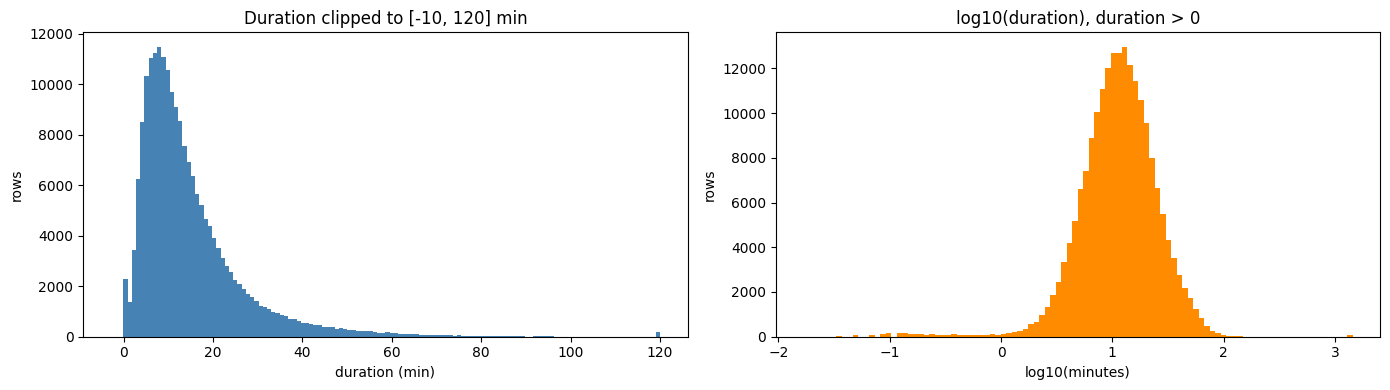

In [8]:
# TODO 1: create raw["duration_min"] in minutes and describe() it with percentiles .001 .01 .5 .99 .999
raw["duration_min"] = (raw["tpep_dropoff_datetime"] - raw["tpep_pickup_datetime"]).dt.total_seconds() / 60
print(raw["duration_min"].describe(percentiles=[.001, .01, .5, .99, .999]))

print("===========================")
# TODO 2: count rows with duration <= 0, > 180 and > 1440 minutes
d = raw["duration_min"]
print(f"duration <= 0   : {(d <= 0).sum():,} ({(d <= 0).mean():.3%})")
print(f"duration > 180  : {(d > 180).sum():,} ({(d > 180).mean():.3%})")
print(f"duration > 1440 : {(d > 1440).sum():,} ({(d > 1440).mean():.3%})")

print("===========================")
# TODO 3: plot two histograms: duration clipped to [-10, 120], and log10(duration) for duration > 0
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(d.clip(-10, 120), bins=130, color="steelblue")
axes[0].set_title("Duration clipped to [-10, 120] min")
axes[0].set_xlabel("duration (min)"); axes[0].set_ylabel("rows")
axes[1].hist(np.log10(d[d > 0]), bins=100, color="darkorange")
axes[1].set_title("log10(duration), duration > 0")
axes[1].set_xlabel("log10(minutes)"); axes[1].set_ylabel("rows")
plt.tight_layout(); plt.show()

In [9]:
d = raw["duration_min"]
raw["pickup_hour"] = raw["tpep_pickup_datetime"].dt.hour
cols = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "duration_min", "trip_distance",
        "fare_amount", "total_amount", "VendorID", "PULocationID", "DOLocationID", "payment_type"]

print(raw.loc[d <= 0, cols].head(10))
print(raw.loc[d > 180, cols].sort_values("duration_min", ascending=False).head(10))
print("rows > 20 h:", (d > 1200).sum())

      tpep_pickup_datetime tpep_dropoff_datetime  duration_min  trip_distance  fare_amount  total_amount  VendorID  PULocationID  \
2328   2024-01-01 10:01:27   2024-01-01 10:01:27           0.0            0.0         0.00          0.00         1           239   
3851   2024-01-01 16:09:38   2024-01-01 16:09:38           0.0            0.0         3.00          4.50         2           264   
4593   2024-01-01 18:56:57   2024-01-01 18:56:57           0.0            0.0         4.40          8.40         1            68   
7055   2024-01-02 12:17:24   2024-01-02 12:17:24           0.0            0.0       350.26        350.26         1           264   
10099  2024-01-02 22:03:05   2024-01-02 22:03:05           0.0            0.0         5.10         10.10         1            48   
12703  2024-01-03 14:00:09   2024-01-03 14:00:09           0.0            0.0         0.00          6.75         1           138   
22967  2024-01-05 00:17:06   2024-01-05 00:17:06           0.0            0.

In [10]:
assert "duration_min" in raw.columns, "create the duration_min column"
print("✅ duration_min exists; median =", round(raw.duration_min.median(), 1), "min")

✅ duration_min exists; median = 11.6 min


## Step 2c – Distance, fare and speed (sanity checks)

Combine columns to test physical plausibility. A single column can look fine while the combination is impossible.

### 🤔 Think first

1. How many trips have distance = 0? Fare ≤ 0? Are they the same rows?
2. Compute the average speed (miles per hour) = distance / duration in hours. What speeds are impossible in New York City?
3. Which upper limits (distance, speed) would you choose, and what evidence from the percentiles supports your choice?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:**

    **Counts:** **3,980 trips (1.99%)** have `trip_distance = 0` and **2,679 trips (1.34%)** have `fare_amount <= 0`.

    **Are they the same rows?** No. Only **259 rows** have both, which is 6.5% of the zero-distance trips and 9.7% of the non-positive fares. They are two different problems with different causes:
    - Most zero-distance trips (3,721 of 3,980) have a **positive fare** (median 16.50 dollars), so they are not empty records. Many have a realistic duration (median 6.7 min), which suggests real trips whose distance was not recorded, while about a quarter last 15 seconds or less and look like cancelled trips.
    - The non-positive fares are mostly payment adjustments: grouped by `payment_type`, 57.6% are disputes, 15.1% are no-charge trips, 21.9% are cash, 5.0% are Flex Fare and only 0.4% are card payments. The ride usually happened, but the payment was refunded, contested or not charged.

    A single rule such as "distance = 0 means invalid" would therefore remove about 3,700 trips that have a positive fare and often a plausible duration.

- **Q2:**

    **Average speed:** `speed_mph = trip_distance / (duration_min / 60)`, computed only where the duration is positive (199,948 rows). The median is **9.6 mph**, the 99th percentile 36.9 mph and the 99.9th percentile 48.9 mph, which is realistic for city traffic with some highway segments.

    **Impossible speeds:**
    - **Too fast:** an *average* speed above about 80 mph is impossible for a taxi in New York City, since an average includes stops at lights and traffic and local speed limits are far lower. This affects **65 trips (0.033%)**, with an absurd maximum of 312,754 mph, which shows that the distance or the duration is wrong.
    - **Almost zero over a long time:** a speed below 1 mph over several hours means the taxi did not move. This is the case of the trips lasting almost 24 hours (for example 4.1 miles in 1,439 minutes, about 0.17 mph), where the dropoff timestamp is wrong. These rows are caught by the duration rule and not by the speed threshold.

    Speed is a useful check because distance (from the meter) and duration (from the timestamps) are two independent measurements, so an inconsistency between them reveals an error that no single column shows.

- **Q3:**

    **Upper limits:** I would keep trips with **speed <= 80 mph** and **distance <= 100 miles**, together with the duration limits chosen earlier (0 < duration <= 180 min). The thresholds define the range of valid values, and everything above them is removed.

    **Evidence for the speed limit:** the 99.9th percentile is **48.9 mph**, so almost no real trip lies between 49 and 80 mph and the threshold falls in an empty region of the distribution. An average above 80 mph is physically impossible in the city, so the rule removes only clearly wrong rows (65 trips). A stricter limit of 60 mph would also be defensible, but 80 is more conservative and limits the risk of removing real fast trips.

    **Evidence for the distance limit:** the 99th percentile is **19.95 miles** and the 99.9th percentile **29.47 miles**, while the maximum is **72,975.97 miles**, more than twice the circumference of the Earth. Only one row exceeds 100 miles, so a cap at 100 miles removes only the absurd value and keeps all realistic long trips, such as airport or out-of-city rides. This rule is redundant with the speed rule for that row, but it stays as an explicit and easy-to-explain check.

    In general, the thresholds are placed in the sparse part of the distribution and justified by physical context, so that errors are removed without cutting legitimate long trips.

In [11]:
# TODO 1: compute raw["speed_mph"] (careful with duration <= 0)
raw["speed_mph"] = (raw["trip_distance"] / (raw["duration_min"] / 60)).where(raw["duration_min"] > 0)

print("===========================")
# TODO 2: describe trip_distance, fare_amount, total_amount, speed_mph with percentiles .01 .5 .99 .999
print(raw[["trip_distance", "fare_amount", "total_amount", "speed_mph"]]
      .describe(percentiles=[.01, .5, .99, .999]).round(2))

print("===========================")
# TODO 3: count distance == 0, fare <= 0, speed > 80, and the overlap between distance == 0 and fare <= 0
zero_dist = raw["trip_distance"] == 0
bad_fare  = raw["fare_amount"] <= 0
too_fast  = raw["speed_mph"] > 80

print(f"distance == 0              : {zero_dist.sum():,} ({zero_dist.mean():.3%})")
print(f"fare <= 0                  : {bad_fare.sum():,} ({bad_fare.mean():.3%})")
print(f"speed > 80 mph             : {too_fast.sum():,} ({too_fast.mean():.3%})")
print(f"distance == 0 AND fare <= 0: {(zero_dist & bad_fare).sum():,}")

       trip_distance  fare_amount  total_amount  speed_mph
count      200000.00    200000.00     200000.00  199948.00
mean            3.58        18.11         26.72      13.54
std           163.23        18.15         22.77     709.60
min             0.00      -700.00       -695.75       0.00
1%              0.00        -5.80        -10.50       0.00
50%             1.67        12.80         20.00       9.57
99%            19.95        75.10        103.30      36.90
99.9%          29.47       143.70        172.95      48.90
max         72975.97       591.70        623.71  312754.16
distance == 0              : 3,980 (1.990%)
fare <= 0                  : 2,679 (1.340%)
speed > 80 mph             : 65 (0.033%)
distance == 0 AND fare <= 0: 259


In [12]:
# 1. Les tarifs <= 0 correspondent-ils à des paiements annulés ou contestés ?
print(raw.loc[bad_fare, "payment_type"].value_counts(normalize=True).round(3))

# 2. Les courses à distance 0 mais tarif positif ont-elles une durée normale ?
print(raw.loc[zero_dist & ~bad_fare, ["duration_min", "fare_amount"]].describe())

# 3. Combien de distances absurdes ?
print("distance > 100 miles:", (raw["trip_distance"] > 100).sum())

payment_type
4    0.576
2    0.219
3    0.151
0    0.050
1    0.004
Name: proportion, dtype: float64
       duration_min  fare_amount
count   3721.000000  3721.000000
mean      10.296762    26.541268
std       20.936568    32.118073
min        0.000000     0.010000
25%        0.250000     7.900000
50%        6.733333    16.500000
75%       15.716667    30.680000
max     1030.183333   577.960000
distance > 100 miles: 1


## Step 2d – Time integrity

Time columns are the backbone of an MLOps pipeline (splits, batches, drift). Check them with suspicion.

### 🤔 Think first

1. The file is called `yellow_tripdata_2024-01`. Do all pickups fall in January 2024? How many do not and which dates do they have?
2. Why would a *monthly* file contain pickups from another year? What does this tell you about the upstream system?
3. How many trips have dropoff earlier than or equal to pickup?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:**

    **Do all pickups fall in January 2024?** Almost all, but not all. In the 200,000-row sample, **2 pickups (0.001%)** fall outside January 2024, and both are before the month:
    - **2023-12-31 23:56:46**, with a dropoff on 2024-01-01 at 00:12:06 (duration 15.3 min)
    - **2023-12-31 23:58:35**, with a dropoff on 2024-01-01 at 00:13:06 (duration 14.5 min)

    No pickup falls after 31 January. Both rows are valid trips with realistic durations that cross midnight, so they are not data errors.

- **Q2:**

    **Why would a monthly file contain pickups from another year?** The two trips started on 31 December 2023 and ended in January, so they appear in the January file because their dropoff (or record time) is in January. This shows that the file is not strictly delimited by pickup date. With only two rows I cannot prove the exact rule, but the pattern is consistent with files being grouped by dropoff or recording time and not by pickup time.

    **What does this tell us about the upstream system?**
    - The data is assembled from several sources (the meter vendors) and published as monthly batches, so a batch is defined by a publication rule and not by a guarantee about its content.
    - The file name is not a contract: `yellow_tripdata_2024-01` announces a month, but nothing guarantees that every row belongs to it. Month boundaries are blurry, and TLC files are also known to contain stray dates in some months.
    - A pipeline must therefore never trust the file name. It has to enforce its own definition of the batch (here, pickup inside `[2024-01-01, 2024-02-01)`) and validate dates at ingestion, otherwise the temporal split and the drift comparison between months would be unreliable. Note that a dropoff after the end of the month is normal (a trip starting on the evening of 31 January), and only the pickup defines the month of a trip.

- **Q3:**

    **Trips with dropoff earlier than or equal to pickup:** **52 trips (0.026%)**, which is the same count as `duration_min <= 0` since the two conditions are equivalent. Most of the inspected rows have a pickup and a dropoff on exactly the same second (duration 0), and a few have a dropoff before the pickup (the minimum duration is -2.9 min). These are recording errors or cancelled trips, and they are removed with the rule `duration > 0`.



In [13]:
# TODO 1: using month_bounds(REF_MONTH), count pickups outside the month
start, end = month_bounds(REF_MONTH)
pickup = raw["tpep_pickup_datetime"]
outside = (pickup < start) | (pickup >= end)
print(f"pickups outside {REF_MONTH}: {outside.sum():,} ({outside.mean():.3%})")

print("===========================")
# TODO 2: which year-months do those out-of-range pickups belong to? (value_counts of dt.to_period("M"))
print(pickup[outside].dt.to_period("M").value_counts().sort_index())

print("===========================")
# TODO 3: count rows where dropoff <= pickup
bad_order = raw["tpep_dropoff_datetime"] <= pickup
print(f"dropoff <= pickup: {bad_order.sum():,} ({bad_order.mean():.3%})")

pickups outside 2024-01: 2 (0.001%)
tpep_pickup_datetime
2023-12    2
Freq: M, Name: count, dtype: int64
dropoff <= pickup: 52 (0.026%)


In [14]:
print(raw.loc[outside, ["tpep_pickup_datetime", "tpep_dropoff_datetime", "duration_min"]])

  tpep_pickup_datetime tpep_dropoff_datetime  duration_min
0  2023-12-31 23:56:46   2024-01-01 00:12:06     15.333333
1  2023-12-31 23:58:35   2024-01-01 00:13:06     14.516667


## Step 2e – Categorical codes

Many columns are *codes*, not quantities. Their meaning lives in the data dictionary, not in the data.

### 🤔 Think first

1. For `payment_type`, `RatecodeID`, `VendorID`, `passenger_count`: what values appear and with what frequency?
2. Compare with the data dictionary. Are there codes that are undocumented or surprising (e.g. `passenger_count` = 0 or > 6)?
3. Which of these columns should be treated as categorical in a model, even though they are numbers?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:**

    **Values and frequencies** (200,000-row sample, missing values included):

    | Column | Values and frequencies |
    |---|---|
    | `payment_type` | 1: 78.19% / 2: 14.76% / 0: 4.76% / 4: 1.62% / 3: 0.68% |
    | `RatecodeID` | 1: 89.79% / NaN: 4.76% / 2: 3.39% / 99: 0.93% / 5: 0.65% / 3: 0.25% / 4: 0.23% |
    | `VendorID` | 2: 75.29% / 1: 24.70% / 6: 0.01% |
    | `passenger_count` | 1: 73.67% / 2: 13.85% / NaN: 4.76% / 3: 3.04% / 4: 1.73% / 5: 1.14% / 0: 1.08% / 6: 0.74% / 8: about 0% |

    Each column is dominated by one value (credit card, standard rate, vendor 2, one passenger) followed by a long tail of rare values. The share of Flex Fare trips (`payment_type = 0`, 4.76%) is exactly the share of missing values in `RatecodeID` and `passenger_count`.

- **Q2:**

    **Comparison with the data dictionary:** all codes present in `payment_type` (0 to 4) and `VendorID` (1, 2, 6) are documented, and `RatecodeID` only takes documented codes (1 to 5 and 99). No undocumented code appears in these three columns. The surprising points are:
    - **Two kinds of "unknown" in `RatecodeID`:** the dictionary defines `99` as null/unknown (0.93%), but the column also contains true missing values (NaN, 4.76%), which are not documented. About 5.7% of the rows therefore have an unknown rate code, and both forms must be handled together.
    - **`passenger_count = 0` (1.08%):** a trip without passengers is physically meaningless. The dictionary gives no valid range because the value is entered by the driver, so this is probably a default entry or an error.
    - **`passenger_count` of 6 (0.74%) and especially 8:** unlikely for an ordinary taxi. The counts are small, but these values are suspicious.
    - **`VendorID = 6`:** documented but almost absent (0.01%, about 20 rows), so it is a very rare category.

- **Q3:**

    **Columns to treat as categorical, even though they are numbers:**
    - `payment_type`, `RatecodeID` and `VendorID`: the numbers are labels with no order or distance (card, cash, dispute; standard, JFK, Newark; vendor identities). Code 5 is not "more" than code 2.
    - `PULocationID` and `DOLocationID`: identifiers of taxi zones (about 260 values). A larger ID means nothing, and these are high-cardinality categories that need careful encoding.

    **`passenger_count` stays numeric:** it is a real count with an order and a meaningful distance (4 passengers is more than 2). It can be capped to limit the influence of the rare and suspicious values (0 and 6 or more).

    **Why it matters:** if codes are given to a model as raw numbers, it may infer relations that do not exist (for example that zone 200 is "larger" than zone 100). They should be declared as categories (the `category` dtype for `HistGradientBoostingRegressor`, or a suitable encoding). Note that `payment_type` and `RatecodeID` are only known at the end of the trip, so they are not allowed as features unless their availability at prediction time is justified. If they were used, they would still be categorical.

In [15]:
# TODO: for each of payment_type, RatecodeID, VendorID, passenger_count print the 10 most frequent values
#       as percentages, INCLUDING missing values (value_counts(dropna=False, normalize=True))
for col in ["payment_type", "RatecodeID", "VendorID", "passenger_count"]:
    print(f"--- {col} ---")
    print((raw[col].value_counts(dropna=False, normalize=True).head(10) * 100).round(2))
    print()

--- payment_type ---
payment_type
1    78.19
2    14.76
0     4.76
4     1.62
3     0.68
Name: proportion, dtype: float64

--- RatecodeID ---
RatecodeID
1.0     89.79
NaN      4.76
2.0      3.39
99.0     0.93
5.0      0.65
3.0      0.25
4.0      0.23
Name: proportion, dtype: float64

--- VendorID ---
VendorID
2    75.29
1    24.70
6     0.01
Name: proportion, dtype: float64

--- passenger_count ---
passenger_count
1.0    73.67
2.0    13.85
NaN     4.76
3.0     3.04
4.0     1.73
5.0     1.14
0.0     1.08
6.0     0.74
8.0     0.00
Name: proportion, dtype: float64



## Step 2f – Relationships: what will the model learn from?

Only look at *plausible* trips here, so extreme values do not hide the signal.

### 🤔 Think first

1. Filter to plausible trips (e.g. 1 ≤ duration ≤ 180 min and 0.1 ≤ distance ≤ 100 mi). How strongly do distance and duration relate? Which axes scale make it readable?
2. How does the **median** duration change by pickup hour and weekday? Why median instead of mean?
3. Given 1 and 2, which features will matter for our prediction – and which of them can we *not* use at prediction time?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:**

    **Filter and strength of the relationship:** I kept plausible trips with `1 <= duration <= 180` min, `0.1 <= distance <= 100` miles and an average speed of at most 80 mph, which leaves **194,989 trips (97.49% of the sample)**. On these trips, distance and duration are **strongly and positively related**: the cloud follows roughly a straight line with a slope close to 1 on a log-log plot, so duration is approximately proportional to distance. The dispersion remains large, though: for a distance of about 1 mile, durations range from roughly 2 to 30 minutes, because traffic, lights and the route change the time for the same distance. Two further features are visible: a floor of about 1 to 3 minutes even for very short distances (start-up and waiting time), and a cluster around 15 to 20 miles with 30 to 60 minutes, probably airport trips.

    **Readable scale:** a **log-log scale** (both axes logarithmic). Distance and duration are strongly right-skewed and span several orders of magnitude, so on linear axes almost all points would be squeezed near the origin and the few long trips would stretch the axes. The logarithmic scale spreads the points and turns the relationship into an elongated cloud around a line. The sharp edges at 1 minute and 0.1 mile come from the filter, not from the data.

- **Q2:**

    **Median duration by pickup hour and weekday:** the median duration varies by hour from about **10.0 min** (around 2-3 am and 6 am) to about **12.5 min** (around 2 pm), with long durations in the middle of the day and a decrease in the evening. The irregularities at night (a peak at 5 am) probably come from the small number of trips at those hours or from a different trip mix, such as airport trips. By weekday, the median is highest on **Thursday (about 12.35 min)** and lowest on **Sunday (about 10.65 min)**, with weekdays slower than the weekend, which is consistent with heavier traffic during the week. The effects are real but modest: about 2.5 minutes across hours and 1.7 minutes across weekdays, for an overall median of about 11.6 minutes. The patterns are almost identical with the stricter and the looser plausibility filter, so the conclusions do not depend on the exact filter. Since the data covers a single month, each weekday appears only four or five times, so special days can shift a median.

    **Why the median instead of the mean:** the duration distribution is right-skewed with a long tail (mean 15.5 min versus median 11.6 min), so a few very long trips pull the mean upward and make it unstable, especially in groups with few trips. The median is robust to such extreme values and describes the typical trip. It is also consistent with the MAE metric, which is minimised by predicting the median.

- **Q3:**

    **Features that matter and are available at prediction time:**
    - **Pickup zone and dropoff zone** (`PULocationID`, `DOLocationID`): they determine the length of the route, which is the largest source of variation in duration, so they are likely the most informative features. Using the dropoff zone assumes that the destination is stated when the ride starts.
    - **Pickup hour and weekday**, derived from `tpep_pickup_datetime`: a real but weak signal, since an effect of about 2 minutes is small compared with the spread of durations, which ranges from several minutes to several tens of minutes depending on the trip.
    - `passenger_count` and `VendorID`: probably a minor effect.

    **Features we cannot use at prediction time:**
    - **`trip_distance`:** it is the variable most strongly related to the duration (Q1), but it is only measured by the meter during the trip and is known at the end, so using it would be target leakage. It could be replaced by an estimate based on the pickup and dropoff zones.
    - **All amounts** (`fare_amount`, `tip_amount`, `tolls_amount`, `total_amount`, surcharges): they are computed from the trip itself and are only known after it.
    - **`payment_type` and `tpep_dropoff_datetime`:** known only when the trip ends (the dropoff time is used only to build the target).
    - **`RatecodeID`:** defined as the final rate code at the end of the trip, so it should be excluded unless its availability at the start can be justified.

    The exploration therefore shows that the strongest explanatory variable is precisely the one we are not allowed to use, so the model has to recover that information from what is known when the ride starts, mainly the pickup and dropoff zones.

plausible trips: 194,989 (97.49% of the sample)


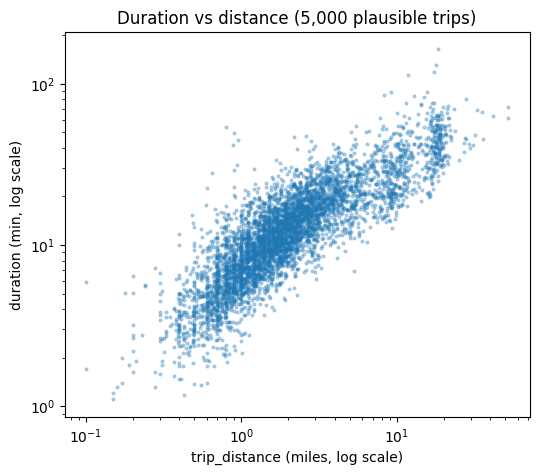

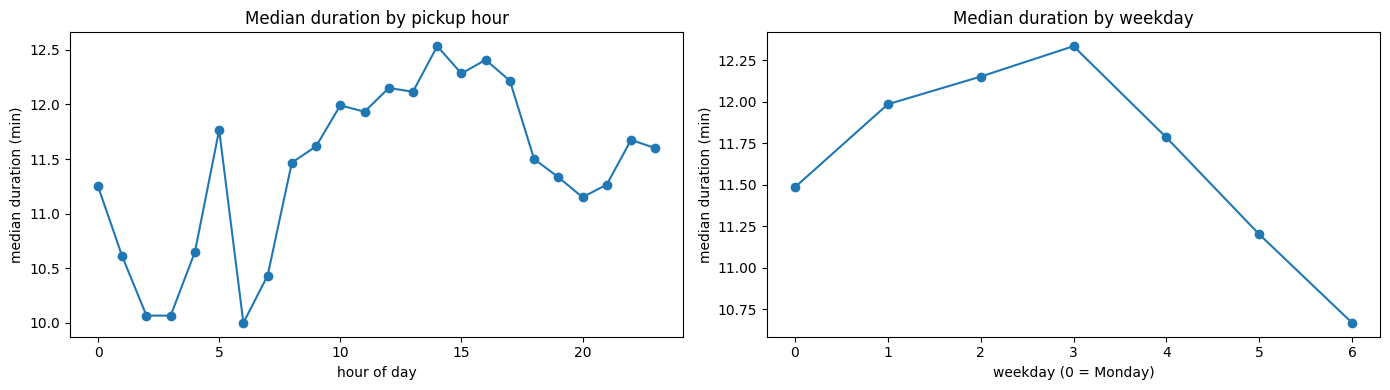

In [16]:
# TODO 1: ok = plausible trips only (choose your own limits from 2b/2c)
ok = raw[(raw["duration_min"].between(1, 180))
         & (raw["trip_distance"].between(0.1, 100))
         & (raw["speed_mph"] <= 80)].copy()
print(f"plausible trips: {len(ok):,} ({len(ok)/len(raw):.2%} of the sample)")

print("===========================")
# TODO 2: scatter duration vs distance on a sample of ~5000 rows, log-log
s = ok[ok["trip_distance"] > 0].sample(5000, random_state=SEED)
plt.figure(figsize=(6, 5))
plt.scatter(s["trip_distance"], s["duration_min"], s=4, alpha=0.3)
plt.xscale("log"); plt.yscale("log")
plt.xlabel("trip_distance (miles, log scale)"); plt.ylabel("duration (min, log scale)")
plt.title("Duration vs distance (5,000 plausible trips)")
plt.show()

print("===========================")
# TODO 3: line plots of the MEDIAN duration by pickup hour and by weekday (0 = Monday)
ok["pickup_hour"] = ok["tpep_pickup_datetime"].dt.hour
ok["pickup_weekday"] = ok["tpep_pickup_datetime"].dt.weekday

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ok.groupby("pickup_hour")["duration_min"].median().plot(ax=axes[0], marker="o")
axes[0].set_title("Median duration by pickup hour")
axes[0].set_xlabel("hour of day"); axes[0].set_ylabel("median duration (min)")
ok.groupby("pickup_weekday")["duration_min"].median().plot(ax=axes[1], marker="o")
axes[1].set_title("Median duration by weekday")
axes[1].set_xlabel("weekday (0 = Monday)"); axes[1].set_ylabel("median duration (min)")
plt.tight_layout(); plt.show()

## Step 2g – From findings to decisions

Turn your EDA into **explicit, numeric rules**. Each rule needs a justification you could defend in a code review.

### 🤔 Think first

1. List every problem you found. For each: drop the row, fix the value, set it to missing, or keep it? Why?
2. Which rules would you also want to apply to **future** monthly batches?
3. What is the cost of being too strict? Too lenient?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:**

    **Problems found and decision for each:**

    | Problem | Size | Decision | Why |
    |---|---|---|---|
    | Pickup outside the month (December 2023) | 2 rows | **Drop** | The monthly batch is defined by pickup time, which keeps the temporal split and the drift comparison unambiguous. These are valid trips, so this is a scoping choice and not a quality fix |
    | Dropoff <= pickup (duration <= 0) | 52 rows | **Drop** | The target is impossible and cannot be reconstructed |
    | Duration below 1 minute | about 1.2% | **Drop** | Cancelled trips or meters started and stopped immediately |
    | Duration above 180 min | 121 rows, 89 of them about 24 h | **Drop** | Normal trips with a wrong dropoff timestamp, so the true duration is unrecoverable |
    | Average speed above 80 mph | 65 rows | **Drop** | Distance and duration are inconsistent, and the speed is physically impossible |
    | Distance above 100 miles | 1 row (72,976 miles) | **Drop** | Impossible, and also caught by the speed rule |
    | Negative fare | at least about 1% of rows | **Drop** | 82.7% have an identical twin with a positive fare, so they are reversal records of trips already in the data and keeping them would count trips twice |
    | Distance = 0 | 3,980 rows (1.99%) | **Keep** if the duration is valid | 93% have a positive fare and many have a normal duration. Distance is not a model feature, so this does not invalidate the target |
    | Missing `passenger_count` | 4.76% (all Flex Fare trips) | **Keep**, add an indicator, then impute | This is a real trip category that also appears in production, so dropping it would leave the model blind on it |
    | `passenger_count` = 0 or above 6 | 1.08% for 0, almost nothing for 8 | **Set to missing** | The trip is valid, only the driver's entry is doubtful |
    | `RatecodeID` = 99 and NaN | 0.93% and 4.76% | **Keep**, merge into one "unknown" category | Two forms of unknown to unify (the column is not an allowed feature anyway) |
    | `VendorID` = 6 | 0.01% | **Keep**, group into "other" | A nearly empty category, handled at encoding time |

    No value is "fixed": a wrong timestamp cannot be reliably repaired (the real end of a "24-hour" trip is unknown), so rows are either dropped or the doubtful field is set to missing, and no value is invented.

- **Q2:**

    **Rules to apply to future monthly batches:**
    - The **same validity rules**, stored in one place (the `R` dictionary), with the batch window computed per month by `month_bounds(ym)`.
    - **Schema validation** at ingestion: expected columns and types, and detection of columns that appear or disappear (for example `cbd_congestion_fee` since 2025).
    - **Code validation:** any value of `payment_type`, `RatecodeID` or `VendorID` that is not in the data dictionary raises an alert (a new vendor or payment type).
    - A **hash of the raw file** stored in a manifest, and the raw file kept untouched.
    - A **cleaning report per batch** with the number of rows removed by each rule, and an alert when a rule removes much more than in the reference month. A jump signals an upstream change, such as a vendor shifting its timestamps.
    - **Re-validation of the thresholds** instead of freezing them: the 180-minute and 80-mph limits come from the January percentiles and must be checked on later months (summer, snow, special events).
    - The **list of allowed features** (no distance, no amounts, no payment type).

- **Q3:**

    **Cost of being too strict:**
    - Real but rare trips (airport rides, long trips in heavy traffic) are removed, so the model does not learn them and **underestimates** them, which is the costliest error for a passenger.
    - Whole segments are lost (Flex Fare trips at 4.8%, vendor 6), which biases the training sample and leaves the model unable to handle what will arrive in production.
    - Metrics on the cleaned data look better than reality, because the hard cases were removed.

    **Cost of being too lenient:**
    - Errors stay in the **target** (for example 24-hour trips) and dominate error-sensitive metrics such as RMSE, which degrades training.
    - Duplicates (the negative-fare reversal records) count the same trips several times.
    - Drift alerts become noisy and trust in the results drops.

    **How to balance:** place thresholds in the sparse parts of the distributions and justify them with physical context, measure the number of rows each rule removes, and check for bias by comparing removed and kept rows on vendor, zone and hour. The most convincing test is empirical: compare the model error with and without a given rule.

In [17]:
# Fill in YOUR thresholds, based on the evidence you collected above. None means "not decided yet".
R = dict(MIN_DURATION=1,   MAX_DURATION=180,   # minutes
         MIN_DISTANCE=0,   MAX_DISTANCE=100,   # miles
         MAX_SPEED=80,                         # mph
         MIN_FARE=0,                           # dollars
         PAX_MIN=1,        PAX_MAX=6)          # passengers

In [18]:
assert all(v is not None for v in R.values()), "Fill in every threshold in R using your EDA"
print("✅ rules defined:", R)

✅ rules defined: {'MIN_DURATION': 1, 'MAX_DURATION': 180, 'MIN_DISTANCE': 0, 'MAX_DISTANCE': 100, 'MAX_SPEED': 80, 'MIN_FARE': 0, 'PAX_MIN': 1, 'PAX_MAX': 6}


## Step 3 – Validation rules (data tests)

A validation rule returns **True for valid rows**. Each rule has a tolerated violation rate: real data is never perfect, but a rule that fails above its tolerance should block the pipeline or raise an alert.

### 🤔 Think first

1. Which of your EDA findings become rules? Write one rule per finding.
2. Why do we use a *tolerance* instead of demanding 0 violations on raw data?
3. On the raw data, which rules fail? On the cleaned data (Step 4) all rules must pass – why is that a useful test?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._



In [19]:
def validate(df, ym, R):
    rows = []
    for name, (fn, max_rate) in make_rules(ym, R).items():
        valid = fn(df).fillna(False); v = int((~valid).sum()); rate = v / len(df)
        rows.append((name, v, round(rate * 100, 3), round(max_rate * 100, 3), "PASS" if rate <= max_rate else "FAIL"))
    return pd.DataFrame(rows, columns=["rule", "violations", "rate_%", "max_rate_%", "status"])

def make_rules(ym, R):
    start, end = month_bounds(ym)
    minutes = lambda d: (d.tpep_dropoff_datetime - d.tpep_pickup_datetime).dt.total_seconds() / 60
    speed = lambda d: (d.trip_distance / (minutes(d) / 60)).where(minutes(d) > 0)   # NaN when duration <= 0
    return {
        # name: (function that returns a boolean Series, True = VALID row,  max tolerated violation rate)
        "dropoff after pickup": (lambda d: d.tpep_dropoff_datetime > d.tpep_pickup_datetime, 0.001),
        "pickup inside file month": (lambda d: d.tpep_pickup_datetime.ge(start) & d.tpep_pickup_datetime.lt(end), 0.001),
        # TODO: add one rule for each finding of your EDA
        "duration in range": (lambda d: minutes(d).between(R["MIN_DURATION"], R["MAX_DURATION"]), 0.02),
        "distance in range": (lambda d: d.trip_distance.between(R["MIN_DISTANCE"], R["MAX_DISTANCE"]), 0.001),
        "speed plausible": (lambda d: speed(d).fillna(0) <= R["MAX_SPEED"], 0.001),
        "fare not negative": (lambda d: d.fare_amount >= R["MIN_FARE"], 0.02),
        "passenger_count valid or missing": (lambda d: d.passenger_count.isna() | d.passenger_count.between(R["PAX_MIN"], R["PAX_MAX"]), 0.02),
        "location ids in 1..265": (lambda d: d.PULocationID.between(1, 265) & d.DOLocationID.between(1, 265), 0.0001),
        "payment_type documented": (lambda d: d.payment_type.isin([0, 1, 2, 3, 4, 5, 6]), 0.0001),
        "RatecodeID documented or missing": (lambda d: d.RatecodeID.isna() | d.RatecodeID.isin([1, 2, 3, 4, 5, 6, 99]), 0.0001),
        "VendorID documented": (lambda d: d.VendorID.isin([1, 2, 6, 7]), 0.0001),
        "passenger_count not null": (lambda d: d.passenger_count.notna(), 0.10),
    }

report_raw = validate(raw, REF_MONTH, R); display(report_raw)

,rule,violations,rate_%,max_rate_%,status
0,dropoff after pickup,52,0.026,0.10,PASS
1,pickup inside file month,2,0.001,0.10,PASS
2,duration in range,2483,1.242,2.00,PASS
3,distance in range,1,0.001,0.10,PASS
4,speed plausible,65,0.033,0.10,PASS
5,fare not negative,2624,1.312,2.00,PASS
6,passenger_count valid or missing,2157,1.079,2.00,PASS
7,location ids in 1..265,0,0.000,0.01,PASS
8,payment_type documented,0,0.000,0.01,PASS
9,RatecodeID documented or missing,0,0.000,0.01,PASS


In [20]:
assert len(report_raw) >= 8, "write at least 8 rules"
print("✅", len(report_raw), "rules,", int((report_raw.status == 'FAIL').sum()), "failing on raw data")

✅ 12 rules, 0 failing on raw data


## Step 4 – Clean (deterministic fixes) and keep a log

Cleaning code must be a **function** (so it can be re-run on every new month) and must **log what it removed**. Fixes here must not learn anything from the data.

### 🤔 Think first

1. Which of your rules should drop rows, and which should only set a value to missing? Why?
2. Does the **order** of the cleaning steps matter? (Hint: speed needs a valid duration.)
3. After cleaning, did you change the *population*? Compare the distribution of `PULocationID` before and after – are some zones losing more rows than others?
4. Why do we also create `pickup_hour`, `pickup_dow`, `pickup_day` here?

### ✍️ Your answers

_Double-click and write your answers before coding ._

- **Q1:**

    **Rows to drop:** rows where the trip or the target is invalid and cannot be repaired:
    - pickup outside the file month (the monthly batch is defined by pickup time);
    - duration outside [1, 180] minutes (aborted meter starts shorter than one minute, and wrong timestamps of about 24 hours);
    - distance above 100 miles and average speed above 80 mph (distance and duration are inconsistent);
    - negative fare (82.7% of these rows have an identical twin with a positive fare, so they are reversal records of trips already in the data).

    **Values to set to missing:** `passenger_count` outside [1, 6] (zero passengers or more than six). The trip itself is valid and its duration is usable, only the driver's entry is doubtful, so the row is kept and the field becomes `NaN`.

    **Rows deliberately kept:** zero-distance trips with a positive fare (distance is not a model feature and many have a plausible duration), fares of exactly 0, and Flex Fare trips with their missing `passenger_count` and `RatecodeID`, which form a real segment (4.8%) that will also appear in production.

- **Q2:**

    **Yes, but mainly for correctness and traceability, not for the final set of rows.** All filters are conditions combined with a logical AND, so the final set of rows is the same whatever the order. The order matters for three reasons:
    - **Speed needs a valid duration.** With a duration of 0 the division gives infinity or NaN, and with a negative duration it gives a meaningless negative speed that would pass the `<= 80` test. Filtering the duration first means the speed is computed only on durations of at least one minute.
    - **The drop log.** Each row is counted at the first step that removes it, so the numbers depend on the order: the speed step drops 2 rows in the log while the independent validation counts 65, because 63 of them were already removed by the duration, distance or pickup steps.
    - **Steps that modify values** (setting `passenger_count` to missing, creating columns) must come after the filters, so that they are only applied to rows that are kept.

- **Q3:**

    **Did cleaning change the population?** Slightly. Cleaning drops 2.38% of the sample (4,765 of 200,000 rows). No pickup zone changes by more than 0.17 percentage points, so the effect on the zone distribution is small. The most affected zone is 132 (4.91% to 4.75%), which loses about 5.6% of its trips against 2.4% on average. Running the validation rules on that zone alone shows why: 3.2% of its trips violate the duration rule (1.2% overall), and 305 of its 315 duration violations are trips shorter than one minute, while only 10 exceed 180 minutes. These look like aborted meter starts and not like long airport rides, so the cleaning does not remove the long trips that matter most for this zone. The small gains of other zones (for example 236 and 237) are mechanical, since shares sum to 100%. The model error per zone should be checked after training to confirm that no zone is penalised.

- **Q4:**

    **Why create `pickup_hour`, `pickup_dow` and `pickup_day`?** They are derived from the pickup timestamp, which is known when the ride starts, so they involve no leakage.
    - `pickup_hour` and `pickup_dow` (0 = Monday) are **features**: the EDA showed a real but modest effect on the median duration (about 2.5 minutes across hours and 1.7 minutes across weekdays).
    - `pickup_day` (day of the month) is used for the **temporal split** (train on the first days, validate on the last days). It should not be used as a feature, because the model would memorise specific days of January instead of learning patterns that generalise to other months.

    They are created inside the cleaning function so that a single definition is used consistently for training and for later batches.

In [21]:
def clean(df, ym, R):
    d = df[[c for c in KEEP if c in df.columns]].copy(); start, end = month_bounds(ym); log = []   # only raw columns: EDA helper columns must not leak in
    d["duration_min"] = (d.tpep_dropoff_datetime - d.tpep_pickup_datetime).dt.total_seconds() / 60
    steps = [("pickup inside file month", lambda x: x.tpep_pickup_datetime.ge(start) & x.tpep_pickup_datetime.lt(end)),
             ("duration in range",        lambda x: x.duration_min.between(R["MIN_DURATION"], R["MAX_DURATION"])),
             # TODO: add steps for distance, speed (compute it after the duration filter!), and fare
             ("distance in range",        lambda x: x.trip_distance.between(R["MIN_DISTANCE"], R["MAX_DISTANCE"])),
             ("speed plausible",          lambda x: (x.trip_distance / (x.duration_min / 60)) <= R["MAX_SPEED"]),
             ("fare not negative",        lambda x: x.fare_amount >= R["MIN_FARE"]),
            ]
    for name, fn in steps:
        before = len(d); d = d[fn(d).fillna(False)]; log.append((name, before - len(d)))
    d = d.copy()
    # TODO: set passenger_count outside [PAX_MIN, PAX_MAX] to NaN (keep the row)
    pax_bad = d.passenger_count.lt(R["PAX_MIN"]) | d.passenger_count.gt(R["PAX_MAX"])
    d.loc[pax_bad, "passenger_count"] = np.nan
    # TODO: add pickup_hour, pickup_dow (0=Mon) and pickup_day (day of month) columns
    d["pickup_hour"] = d.tpep_pickup_datetime.dt.hour
    d["pickup_dow"]  = d.tpep_pickup_datetime.dt.dayofweek
    d["pickup_day"]  = d.tpep_pickup_datetime.dt.day
    return d.reset_index(drop=True), pd.DataFrame(log, columns=["step", "rows_dropped"])

clean_df, drop_log = clean(raw, REF_MONTH, R)
display(drop_log); print(f"{len(raw):,} -> {len(clean_df):,} rows ({100 * (1 - len(clean_df) / len(raw)):.2f}% dropped)")

# TODO: bias check - compare normalized PULocationID counts before (raw) and after (clean_df);
#       show the 5 zones with the largest absolute change in percentage points
b = raw["PULocationID"].value_counts(normalize=True)
a = clean_df["PULocationID"].value_counts(normalize=True)
cmp = pd.DataFrame({"raw_%": b * 100, "clean_%": a * 100}).fillna(0)
cmp["change_pp"] = cmp["clean_%"] - cmp["raw_%"]
display(cmp.reindex(cmp["change_pp"].abs().sort_values(ascending=False).index).head(5).round(3))

,step,rows_dropped
0,pickup inside file month,2
1,duration in range,2483
2,distance in range,1
3,speed plausible,2
4,fare not negative,2277


200,000 -> 195,235 rows (2.38% dropped)


,raw_%,clean_%,change_pp
PULocationID,,,
132,4.908,4.745,-0.163
236,4.599,4.652,0.053
193,0.072,0.023,-0.048
237,4.745,4.792,0.047
265,0.046,0.017,-0.030


In [22]:
assert clean_df.passenger_count.dropna().between(R["PAX_MIN"], R["PAX_MAX"]).all(), "invalid passenger counts remain"
assert {"pickup_hour", "pickup_dow", "pickup_day"} <= set(clean_df.columns), "add the time features"
rep = validate(clean_df, REF_MONTH, R); display(rep)
assert (rep.status == "PASS").all(), "some validation rules still fail on the cleaned data: fix clean() or your rules"
print("✅ cleaned data passes all validation rules")

,rule,violations,rate_%,max_rate_%,status
0,dropoff after pickup,0,0.000,0.10,PASS
1,pickup inside file month,0,0.000,0.10,PASS
2,duration in range,0,0.000,2.00,PASS
3,distance in range,0,0.000,0.10,PASS
4,speed plausible,0,0.000,0.10,PASS
5,fare not negative,0,0.000,2.00,PASS
6,passenger_count valid or missing,0,0.000,2.00,PASS
7,location ids in 1..265,0,0.000,0.01,PASS
8,payment_type documented,0,0.000,0.01,PASS
9,RatecodeID documented or missing,0,0.000,0.01,PASS


✅ cleaned data passes all validation rules


## Step 5 – Time-based split, baseline and the leakage experiment

We simulate production: **train on the past, test on the future**. Then we compare against a trivial baseline and measure what happens if we use a feature that is *not* available at prediction time.

### 🤔 Think first

1. Why a time-based split instead of random? What could a random split hide?
2. Why do we need a **baseline** (e.g. always predict the median)? What does 'good MAE' mean without it?
3. Add `trip_distance` as a feature. The error drops a lot. Is that a better model? Why can't you deploy it?
4. Our tree-based model accepts NaN natively. If you used a linear model, where would you impute missing `passenger_count`, and fitted on which data?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:** A time-based split simulates production: the model is trained on the past (days 1 to 24) and evaluated on the future (days 25 to 31), as it would be after deployment. A random split would hide two problems:
    - **Temporal leakage:** trips from the same day or hour end up in both sets. They share the same traffic, weather and events, so the model has already seen the context of the test trips and the test error looks better than it will be in reality.
    - **Drift:** if the data changes over time (holidays, storms, rule changes), a random shuffle averages this change away. A time-based split exposes it, because the test period was never seen during training.

  A random split would therefore give an optimistic estimate, and the gap would only appear after deployment.

- **Q2:** A baseline gives a scale to read the error. A test MAE of 5.02 minutes means nothing on its own, because we do not know whether the problem is easy or hard. Always predicting the median gives an MAE of 7.72 minutes, so our model reduces the error by about 35%. A good MAE is therefore one that clearly beats the trivial solution. The baseline also protects us in two ways: if the model is not better than the baseline, it adds no value or there is a bug in the pipeline, and it provides a minimum threshold a model must beat before deployment. The median is used because it is the best constant prediction when the error is measured in absolute value.

- **Q3:** No, it is not a better model. Adding `trip_distance` lowers the MAE from 5.02 to 3.11 minutes, but this gain is an illusion caused by data leakage. The prediction is made at the start of the ride, while the measured distance is only known during and at the end of the trip. At prediction time this value does not exist, so the model cannot be deployed, and its score does not reflect its real performance. A distance estimated at booking time by a routing service would be usable, but the actual measured distance would not.

- **Q4:** A linear model cannot handle NaN, so `passenger_count` must be imputed. The imputation should be done inside a scikit-learn `Pipeline`, just before the model (for example `SimpleImputer` followed by `LinearRegression`), and fitted **only on the training set**. The imputation value (median or most frequent value) is computed on the training data and then reused unchanged on the test set and in production. Computing it on the full dataset would let information from the test set leak into training. Since the missing values are structural (they come from Flex Fare trips) and not random, adding a missing-value indicator (`add_indicator=True`) lets the model know that the value was absent.

In [23]:
FEATURES = ["pickup_hour", "pickup_dow", "PULocationID", "DOLocationID", "passenger_count", "VendorID"]
TARGET = "duration_min"; SPLIT_DAY = 24

# TODO 1: train_df = rows with pickup_day <= SPLIT_DAY ; test_df = the rest (the last days of the month)
train_df = clean_df[clean_df["pickup_day"] <= SPLIT_DAY]
test_df  = clean_df[clean_df["pickup_day"] >  SPLIT_DAY]

# TODO 2: print sizes, and the date ranges (min/max pickup) of both sets - do they overlap?
print(f"train: {len(train_df):,} rows | test: {len(test_df):,} rows ({len(test_df) / len(clean_df):.1%} test)")
print("train:", train_df.tpep_pickup_datetime.min(), "->", train_df.tpep_pickup_datetime.max())
print("test :", test_df.tpep_pickup_datetime.min(), "->", test_df.tpep_pickup_datetime.max())
print("overlap:", train_df.tpep_pickup_datetime.max() >= test_df.tpep_pickup_datetime.min())

# TODO 3: baseline = DummyRegressor(strategy="median"); report test MAE (minutes)
y_train, y_test = train_df[TARGET], test_df[TARGET]
baseline = DummyRegressor(strategy="median").fit(train_df[FEATURES], y_train)
mae_base = mean_absolute_error(y_test, baseline.predict(test_df[FEATURES]))
print(f"baseline (median) test MAE: {mae_base:.2f} min")

# TODO 4: model = HistGradientBoostingRegressor(max_iter=200, random_state=SEED); report test MAE
model = HistGradientBoostingRegressor(max_iter=200, random_state=SEED).fit(train_df[FEATURES], y_train)
mae_model = mean_absolute_error(y_test, model.predict(test_df[FEATURES]))
print(f"model, allowed features, test MAE: {mae_model:.2f} min")

# TODO 5: repeat 4 with FEATURES + ["trip_distance"] and compare
FEATURES_D = FEATURES + ["trip_distance"]
model_d = HistGradientBoostingRegressor(max_iter=200, random_state=SEED).fit(train_df[FEATURES_D], y_train)
mae_d = mean_absolute_error(y_test, model_d.predict(test_df[FEATURES_D]))
print(f"model + trip_distance (LEAKAGE), test MAE: {mae_d:.2f} min")

display(pd.DataFrame({"model": ["median baseline", "HGB allowed features", "HGB + trip_distance (leakage)"],
                      "test_MAE_min": [mae_base, mae_model, mae_d]}).round(2))

train: 148,620 rows | test: 46,615 rows (23.9% test)
train: 2024-01-01 00:00:17 -> 2024-01-24 23:59:28
test : 2024-01-25 00:00:50 -> 2024-01-31 23:59:43
overlap: False
baseline (median) test MAE: 7.72 min
model, allowed features, test MAE: 5.02 min
model + trip_distance (LEAKAGE), test MAE: 3.11 min


,model,test_MAE_min
0,median baseline,7.72
1,HGB allowed features,5.02
2,HGB + trip_distance (leakage),3.11


In [24]:
assert len(train_df) > 0 and len(test_df) > 0, "empty split"
assert train_df.tpep_pickup_datetime.max() < test_df.tpep_pickup_datetime.min(), "train must be strictly before test"
print("✅ split OK | baseline MAE:", round(mae_base, 2), "| model MAE:", round(mae_model, 2))

✅ split OK | baseline MAE: 7.72 | model MAE: 5.02


## Step 6 – Version the data and prove reproducibility

A model is reproducible only if you can recover the *exact* data and rules behind it. We use content hashes and a manifest (what DVC / lakeFS / Delta do at scale).

### 🤔 Think first

1. What must a manifest contain so that a colleague can rebuild the training set 6 months from now?
2. Why hash the **raw** file and not only the processed files?
3. How would you *prove* the pipeline is reproducible? Write the test.

### ✍️ Your answers

_Double-click and write your answers before coding ._

- **Q1:** A manifest must contain everything a colleague needs to rebuild the exact training set without asking us anything. It records:
    - **the raw source:** the file name, its SHA-256 and the number of rows in the file;
    - **the sample:** the sample size (200,000) and the random seed (42), which fix which rows are drawn;
    - **the cleaning rules:** all thresholds (duration, distance, speed, fare, passenger count) and the drop log, so the number of rows removed by each step can be checked;
    - **the split rule:** `pickup_day <= 24` for training, the rest for testing;
    - **the modelling setup:** the list of features and the target;
    - **the outputs:** the row counts of the clean, train and test sets, and the SHA-256 of the train and test files, so the rebuilt result can be compared with the original;
    - **the environment:** the creation date and the library versions (such as scikit-learn).

  If any of these fields is missing, something can no longer be replayed or verified. Without the seed we cannot find the same 200,000 rows, and without the thresholds we cannot explain why 4,765 rows were removed.

- **Q2:** The raw file is the root of the whole lineage, because every processed file is derived from it. Hashing only the processed files proves that they were not modified, but not where they came from. Hashing the raw file adds three guarantees:
    1. **Same input:** a file name does not guarantee its content. TLC can republish or correct a monthly file under the same name, and a download can be interrupted or corrupted. Only the SHA-256 proves that the input is identical.
    2. **Faster diagnosis:** if results change and the raw hash is different, the cause is the data. If the hash is the same, the cause is the code or the rules.
    3. **Cheap early check:** the input can be verified before spending time on the rest of the pipeline.

- **Q3:** We prove reproducibility by rebuilding the datasets from scratch with the same code and comparing them with the saved ones. We reload the raw file with the same seed, apply the same cleaning function with the same rules, apply the same split, and then assert that the rebuilt train and test sets are identical to the saved ones. As a stronger check, we write the rebuilt files and compare their SHA-256 with the hashes stored in the manifest.

  ```python
  raw2 = load_month(REF_MONTH)                    # same file, same seed
  clean2, _ = clean(raw2, REF_MONTH, R)           # same rules
  train2 = clean2[clean2["pickup_day"] <= SPLIT_DAY]
  test2  = clean2[clean2["pickup_day"] >  SPLIT_DAY]

  pd.testing.assert_frame_equal(train_df, train2)
  pd.testing.assert_frame_equal(test_df,  test2)

  train2.to_parquet(PROC / "_check_train.parquet")
  assert sha256(PROC / "_check_train.parquet") == manifest["train_sha256"]
  ```

  The test passes: the rebuilt train and test sets are identical in values and in SHA-256. This shows that the pipeline is deterministic, since the same raw file, the same seed and the same code always give the same data. The guarantee holds for the same library versions, which is why the versions are recorded in the manifest.

In [25]:
raw_path = RAW / f"yellow_tripdata_{REF_MONTH}.parquet"

train_df.to_parquet(PROC / "train_v1.parquet"); test_df.to_parquet(PROC / "test_v1.parquet")
manifest = {
    "dataset": "nyc_yellow_taxi_duration", "version": "v1", "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    # TODO: complete the manifest
    "source_file": raw_path.name,
    "source_sha256": sha256(raw_path),
    "rows_in_file": ROWS_IN_FILE[REF_MONTH],
    "sample_size": SAMPLE_N,
    "sample_seed": SEED,
    "cleaning_rules": R,
    "drop_log": drop_log.to_dict("records"),
    "split_rule": f"pickup_day <= {SPLIT_DAY} -> train, else test",
    "features": FEATURES,
    "target": TARGET,
    "rows_clean": len(clean_df),
    "rows_train": len(train_df),
    "rows_test": len(test_df),
    "train_sha256": sha256(PROC / "train_v1.parquet"),
    "test_sha256": sha256(PROC / "test_v1.parquet"),
    "sklearn_version": sklearn.__version__,
}
json.dump(manifest, open(ART / "data_manifest_v1.json", "w"), indent=2, default=str)
print(json.dumps(manifest, indent=2, default=str)[:1200])

# TODO: reproducibility test - rebuild train/test from the raw file with the same code and assert they are identical
raw2 = load_month(REF_MONTH)                       # same file + same seed + same sort
clean2, _ = clean(raw2, REF_MONTH, R)              # same rules
train2 = clean2[clean2["pickup_day"] <= SPLIT_DAY]
test2  = clean2[clean2["pickup_day"] >  SPLIT_DAY]

pd.testing.assert_frame_equal(train_df, train2)    # same values, order and index
pd.testing.assert_frame_equal(test_df,  test2)

# strongest proof: the rebuilt files have the same SHA-256 as the saved ones
train2.to_parquet(PROC / "_check_train.parquet"); test2.to_parquet(PROC / "_check_test.parquet")
assert sha256(PROC / "_check_train.parquet") == manifest["train_sha256"], "train hash differs"
assert sha256(PROC / "_check_test.parquet")  == manifest["test_sha256"],  "test hash differs"
(PROC / "_check_train.parquet").unlink(); (PROC / "_check_test.parquet").unlink()
print("reproducible: rebuilt train/test are identical (values and SHA-256)")

{
  "dataset": "nyc_yellow_taxi_duration",
  "version": "v1",
  "created_utc": "2026-11-15T00:22:36+00:00",
  "source_file": "yellow_tripdata_2024-01.parquet",
  "source_sha256": "c4d59da7bbc8abaeeeb1727947ee93d9891a71acb42854bd80db1571b2030510",
  "rows_in_file": 2964624,
  "sample_size": 200000,
  "sample_seed": 42,
  "cleaning_rules": {
    "MIN_DURATION": 1,
    "MAX_DURATION": 180,
    "MIN_DISTANCE": 0,
    "MAX_DISTANCE": 100,
    "MAX_SPEED": 80,
    "MIN_FARE": 0,
    "PAX_MIN": 1,
    "PAX_MAX": 6
  },
  "drop_log": [
    {
      "step": "pickup inside file month",
      "rows_dropped": 2
    },
    {
      "step": "duration in range",
      "rows_dropped": 2483
    },
    {
      "step": "distance in range",
      "rows_dropped": 1
    },
    {
      "step": "speed plausible",
      "rows_dropped": 2
    },
    {
      "step": "fare not negative",
      "rows_dropped": 2277
    }
  ],
  "split_rule": "pickup_day <= 24 -> train, else test",
  "features": [
    "pickup_hour",


In [37]:
m = json.load(open(ART / "data_manifest_v1.json"))
for k in ["source_sha256", "train_sha256", "test_sha256", "cleaning_rules", "sample_seed"]: assert k in m, f"manifest is missing {k}"
print("✅ manifest has the key fields")

✅ manifest has the key fields


### Optional: the same idea with DVC (run in a terminal, not in the notebook)
```bash
git init && dvc init
dvc add data/raw/yellow_tripdata_2024-01.parquet data/processed/train_v1.parquet data/processed/test_v1.parquet
git add data/raw/*.dvc data/processed/*.dvc .gitignore artifacts/data_manifest_v1.json && git commit -m "data v1"
dvc remote add -d storage <s3-or-local-path> && dvc push      # later: git checkout <commit> && dvc pull
```

## Step 7 – Persist the model with its lineage

Save the model **together with** everything needed to trust and reproduce it.

### 🤔 Think first

1. What information must be stored next to the model file so that an on-call engineer can answer: 'which data trained this and how good was it?'
2. Why store the baseline MAE too?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:** The model file alone is a black box, so a metadata file (`model_v1_meta.json`) must be stored next to it. To answer "which data trained this and how good was it?", it must contain:
    - **the data:** the data version and the SHA-256 of the train and test files. These hashes link the model to the exact datasets used, and through the data manifest back to the raw source file;
    - **the quality:** the test MAE in minutes, measured on data the model has never seen, together with the baseline MAE and the definition of the baseline (see Q2);
    - **the inputs and output:** the list of features and the target, so that anyone using the model knows what to provide and what it predicts;
    - **the training setup:** the algorithm and its hyperparameters (including the random seed), and the library version (scikit-learn), because a serialized model may not reload correctly with another version;
    - **the integrity and age of the file:** the SHA-256 of the model file, to prove that it has not been replaced or modified, and the creation date.

  With these fields, an on-call engineer can answer the question directly from the metadata, without opening the notebook.

- **Q2:** The baseline MAE is stored because an MAE has no meaning on its own: 5.02 minutes could be good or bad depending on how hard the problem is. Stored next to the baseline MAE of 7.72 minutes (always predicting the median of the training set, ignoring all features), it shows immediately that the model reduces the error by about 35%. This reference is useful in three situations:
    - **monitoring:** if the error observed in production moves back toward the baseline value, the model is no better than the trivial solution and action is needed;
    - **comparing versions:** when `model_v2` is trained, the baseline gives a common reference to decide whether to replace the current model;
    - **diagnosis:** without it, the engineer would have to find the notebook and recompute the baseline to know whether a given error is normal.

  The method used to build the baseline (`DummyRegressor` with the median strategy, fitted on the train set) is stored as well, because a value without its definition cannot be compared or reproduced.

In [28]:
joblib.dump(model, ART / "model_v1.joblib")
meta = {"model": "model_v1", "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
        # TODO: add features, target, data version, train/test data sha256 (from the manifest), test MAE, baseline MAE,
        #       sklearn version and the sha256 of the model file
        "algorithm": "HistGradientBoostingRegressor",
        "hyperparameters": {"max_iter": 200, "random_state": SEED},
        "features": FEATURES,
        "target": TARGET,
        "data_version": manifest["version"],
        "train_data_sha256": manifest["train_sha256"],
        "test_data_sha256": manifest["test_sha256"],
        "test_mae_min": round(float(mae_model), 3),
        "baseline_mae_min": round(float(mae_base), 3),
        "baseline_method": "DummyRegressor(strategy='median'), fitted on the train set, ignores features",
        "sklearn_version": sklearn.__version__,
        "model_sha256": sha256(ART / "model_v1.joblib"),
       }
json.dump(meta, open(ART / "model_v1_meta.json", "w"), indent=2); print(json.dumps(meta, indent=2))

{
  "model": "model_v1",
  "created_utc": "2026-11-15T00:32:19+00:00",
  "algorithm": "HistGradientBoostingRegressor",
  "hyperparameters": {
    "max_iter": 200,
    "random_state": 42
  },
  "features": [
    "pickup_hour",
    "pickup_dow",
    "PULocationID",
    "DOLocationID",
    "passenger_count",
    "VendorID"
  ],
  "target": "duration_min",
  "data_version": "v1",
  "train_data_sha256": "e917ecd076a3fa9a4dd7d8d8f4c0a358a585d0baf0f27d32aa13010f7d2de587",
  "test_data_sha256": "9a2bb2260937c0817d2868cbae6d7ca3bb08788274c3d4075993e99595eec740",
  "test_mae_min": 5.024,
  "baseline_mae_min": 7.722,
  "baseline_method": "DummyRegressor(strategy='median'), fitted on the train set, ignores features",
  "sklearn_version": "1.8.0",
  "model_sha256": "609a2e36f1f33f00e991d8c122a81f0e766723916e53a7e1d775bd8490317dfc"
}


In [29]:
mm = json.load(open(ART / "model_v1_meta.json"))
for k in ["features", "train_data_sha256", "test_mae_min", "baseline_mae_min"]: assert k in mm, f"meta is missing {k}"
print("✅ model metadata complete")

✅ model metadata complete


## Step 8 – Monitor new monthly batches

Each new month is a **production batch**. For every batch we run the *same* code: load → validate → clean → compare with the reference → score the model. We use three batches: **2024-02** (neighbour), **2024-07** (season), **2020-04** (COVID shock).

### 🤔 Think first

1. Before running: which batch do you expect to look most like January 2024? Which least? Why?
2. PSI compares two distributions. Which formula, and how do you define the bins for a numeric feature? (Hint: use the *reference* quantiles.) What are the usual thresholds?
3. Taxi labels (duration) are known right after the trip. What does that allow you to monitor that is impossible for, e.g., churn labels that arrive months later?
4. After running: which signal fired first – validation, input drift, or performance? Could there be drift **without** a performance drop, or a performance drop **without** input drift?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:** I expected **2024-02** to look most like January 2024: it is the neighbouring month, in the same season, with the same fare structure, the same regulations and the same data format. I expected **2020-04** to look least like it: the COVID lockdown collapsed demand and changed where and when people travelled, and the period is four years older, with a different fare structure and different payment habits. I expected **2024-07** to be in between, since it is the same year but a different season (tourism, weather, traffic). The results confirmed the two extremes: February has all PSI values at or below 0.005, while April 2020 reaches 0.603 on `fare_amount`. July was more surprising: its input distributions stay close to January (all PSI below 0.03), but its MAE degrades more than February's.

- **Q2:** The Population Stability Index compares the share of observations in each bin for a reference sample (`r`) and a new batch (`c`): PSI = sum over bins of (c - r) x ln(c / r). Each term is positive, so the PSI is 0 when nothing changes and grows with the shift. For a numeric feature, the bin edges are the **quantiles of the reference** (deciles of the training data), so each bin holds about 10% of the reference. Duplicate edges are removed with `np.unique`, and the first and last edges are set to minus and plus infinity so that every new value falls in a bin. The same edges are used for the reference and the new batch, and shares are clipped at 1e-4 to avoid log(0). For categorical features, we keep the 20 most frequent categories of the reference and group the others together. The usual thresholds are: PSI below 0.1 means stable, between 0.1 and 0.25 means a moderate shift to watch, and above 0.25 means a significant shift to investigate.

- **Q3:** Because the trip duration is known right after the trip, we can measure the **real performance** of the model (the MAE) on every new batch almost immediately. This allows us to monitor the quality of the model directly instead of relying only on indirect signals such as input drift. It also lets us detect **concept drift**, where the relationship between the inputs and the duration changes even if the input distributions stay the same, and it keeps the feedback loop short, so a retraining decision can be taken and checked quickly. With labels that arrive months later, such as churn, we could only monitor inputs and predictions during that delay, without knowing whether the model is actually wrong. Our July result shows the value of this: only the MAE signalled a problem.

- **Q4:** The three signals reacted differently depending on the batch:

  | Batch | Validation | Input drift | Performance |
  |---|---|---|---|
  | 2024-02 | no failing rule | all PSI <= 0.005 | MAE +3% |
  | 2024-07 | no failing rule | all PSI < 0.03 | MAE +13% |
  | 2020-04 | 2 rules failing | PSI up to 0.60 | MAE +32% |

  The signals are computed at the same time on each batch, so there is no real order in time. What we can say is that for July **only the performance signal** reacted, while for April 2020 **all three** reacted.

  **A performance drop without input drift** appears in July 2024: the MAE goes from 5.02 to 5.66 minutes while none of the monitored features drifted. This is consistent with concept drift, where the same inputs now lead to a different duration (for example summer traffic or roadworks). This conclusion has limits: the PSI was only computed on six columns, so a drift on the unmonitored model inputs (`DOLocationID`, `pickup_dow`, `VendorID`) or in combinations of features cannot be ruled out.

  **Input drift without a proportional performance drop** is also possible: in April 2020, the largest PSI values concern `fare_amount` (0.60) and `payment_type` (0.28), which are not model features, so they do not affect the model directly. The MAE still rises by 32%, which is a clear degradation, and `PULocationID` (PSI 0.39), which is a model input, probably contributes to it.

  In conclusion, no single signal is enough. Input drift can fire without hurting the model, and performance can drop without any visible input drift, so validation, input drift and performance must be monitored together.

In [30]:
ref = train_df                      # reference = the training data of model v1
model = joblib.load(ART / "model_v1.joblib")
ref_mae = json.load(open(ART / "model_v1_meta.json"))["test_mae_min"]

def _psi(r, c):
    r, c = np.clip(r, 1e-4, None), np.clip(c, 1e-4, None)      # avoid log(0) and division by 0
    return float(np.sum((c - r) * np.log(c / r)))

def psi_numeric(ref, cur, bins=10):
    # TODO: 1) bin edges = quantiles of ref (np.unique to drop duplicates), first/last edge = -inf/+inf
    #       2) r, c = share of ref / cur in each bin (np.histogram), after dropping NaN
    #       3) clip shares at 1e-4, return sum((c - r) * log(c / r))
    ref, cur = ref.dropna(), cur.dropna()
    q = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges = np.concatenate([[-np.inf], q[1:-1], [np.inf]])
    r = np.histogram(ref, bins=edges)[0] / len(ref)
    c = np.histogram(cur, bins=edges)[0] / len(cur)
    return _psi(r, c)

def psi_categorical(ref, cur, top=20):
    # TODO: keep the `top` most frequent categories of ref, group the rest as -1, compare the shares like above
    ref, cur = ref.dropna(), cur.dropna()
    keep = ref.value_counts().head(top).index
    ref_g, cur_g = ref.where(ref.isin(keep), -1), cur.where(cur.isin(keep), -1)
    cats = list(keep) + [-1]
    r = ref_g.value_counts(normalize=True).reindex(cats).fillna(0).to_numpy()
    c = cur_g.value_counts(normalize=True).reindex(cats).fillna(0).to_numpy()
    return _psi(r, c)

NUM_FEATS, CAT_FEATS = ["trip_distance", "fare_amount", "pickup_hour", "passenger_count"], ["payment_type", "PULocationID"]

def monitor(ym):
    b = load_month(ym); val = validate(b, ym, R); c, _ = clean(b, ym, R)
    row = {"month": ym, "rows": len(c), "pct_dropped": round(100 * (1 - len(c) / len(b)), 2), "rules_failing": int((val.status == "FAIL").sum())}
    # TODO: add psi_<feature> for numeric and categorical features, and the model MAE on this batch
    for f in NUM_FEATS: row[f"psi_{f}"] = round(psi_numeric(ref[f], c[f]), 3)
    for f in CAT_FEATS: row[f"psi_{f}"] = round(psi_categorical(ref[f], c[f]), 3)
    row["MAE_min"] = round(mean_absolute_error(c[TARGET], model.predict(c[FEATURES])), 3)
    return row

# TODO: run monitor() for "2024-02", "2024-07", "2020-04" and show a table
report = pd.DataFrame([monitor(ym) for ym in ["2024-02", "2024-07", "2020-04"]])
display(report)

downloading 2024-02 ...
downloading 2024-07 ...
downloading 2020-04 ...


,month,rows,pct_dropped,rules_failing,psi_trip_distance,psi_fare_amount,psi_pickup_hour,psi_passenger_count,psi_payment_type,psi_PULocationID,MAE_min
0,2024-02,195291,2.35,0,0.001,0.003,0.004,0.001,0.004,0.005,5.183
1,2024-07,193751,3.12,0,0.007,0.015,0.002,0.000,0.029,0.012,5.658
2,2020-04,195240,2.38,2,0.039,0.603,0.099,0.023,0.277,0.391,6.612


In [32]:
validate(load_month("2020-04"), "2020-04", R)

,rule,violations,rate_%,max_rate_%,status
0,dropoff after pickup,261,0.131,0.10,FAIL
1,pickup inside file month,110,0.055,0.10,PASS
2,duration in range,3807,1.903,2.00,PASS
3,distance in range,11,0.006,0.10,PASS
4,speed plausible,170,0.085,0.10,PASS
5,fare not negative,1094,0.547,2.00,PASS
6,passenger_count valid or missing,5499,2.749,2.00,FAIL
7,location ids in 1..265,0,0.000,0.01,PASS
8,payment_type documented,0,0.000,0.01,PASS
9,RatecodeID documented or missing,0,0.000,0.01,PASS


In [31]:
assert "report" in globals() and len(report) == 3, "build the monitoring report for the 3 months"
assert any(c.startswith("psi_") for c in report.columns) and "MAE_min" in report.columns
print("✅ monitoring report built")

✅ monitoring report built


## Step 9 – Turn monitoring into a decision

Monitoring without a **decision rule** is just a dashboard. Write the policy as code so it is reviewable and testable.

### 🤔 Think first

1. Define thresholds: when do you only *investigate*, and when do you *retrain*? Use at least one input-drift condition and one performance condition.
2. What do you do for 2020-04? Is retraining on 2020-04 data the right answer? What would you check first?
3. What is the 'v2' of the data: what exactly would you version and what would stay the same?

### ✍️ Your answers

_Double-click and write your answers before coding (one line each is enough)._

- **Q1:** I use both input-drift and performance conditions, with the reference MAE (`ref_mae`, about 5.02 minutes, the model test MAE) as the anchor. A month is flagged **INVESTIGATE** if the maximum PSI is at least 0.10, or the MAE ratio (month MAE divided by `ref_mae`) is at least 1.10, or a validation rule fails. It is flagged **RETRAIN** if the MAE ratio is at least 1.25, or if the maximum PSI is at least 0.25 and the MAE ratio is at least 1.10. Otherwise the status is OK. Input drift alone only triggers an investigation, because the inputs can move without hurting the model, while retraining is reserved for a confirmed loss of performance, either strong by itself (about 1.25 extra minutes of error) or supported by a strong input shift.

- **Q2:** The policy returns RETRAIN for 2020-04, since the inputs shifted strongly (Cramer's V of 0.26 on PULocationID) and the MAE is about 32% above the reference, with hourly ratios up to 1.6 at night. However, retraining on this month is not necessarily the right answer: April 2020 is an exceptional period (lockdown), and a model trained on it would learn an abnormal regime that would perform badly when activity returns to normal. The first thing I would check is the data quality of 2020-04 (the validation report already shows 8.2% missing passenger_count), to know whether the degradation comes from the data or from a real change in behaviour. Then I would compare the model with the median baseline (MAE 7.72) on this month to see whether it is still useful, check whether the shift is temporary by looking at the following months, and confirm that enough representative recent data exists. Meanwhile I would raise an alert and keep the current model in service, and retrain only if the change turns out to be lasting.

- **Q3:** The v2 of the data changes only the inputs. I would version the new source file (its SHA-256), the cleaned train and test files with their hashes (tracked with DVC), a new manifest (row counts, drop log, hashes, creation date) and the model_v2 with metadata pointing to the train hash of the v2. Everything that defines the recipe would stay the same: the pipeline code (same Git commit), the cleaning thresholds, the features, the target, the time-based split rule, the sampling size and the seed. With only the data changing, any difference in the results can be attributed to the data and not to the code. The v1 stays untouched and reproducible, because DVC keeps both versions and a `git checkout` followed by `dvc checkout` brings it back.

In [33]:
# seuils de la politique (à relire et discuter en équipe)
PSI_WARN, PSI_ALERT = 0.10, 0.25      # dérive des entrées : modérée / importante
MAE_WARN, MAE_ALERT = 1.10, 1.25      # MAE du lot relative à la référence : +10 % / +25 %

def decide(row, ref_mae):
    # TODO: return "OK", "INVESTIGATE" or "RETRAIN" using the max PSI of the row and its MAE vs ref_mae
    psi_cols = [c for c in row.index if c.startswith("psi_")]
    max_psi = row[psi_cols].max()
    mae_ratio = row["MAE_min"] / ref_mae

    if mae_ratio >= MAE_ALERT or (max_psi >= PSI_ALERT and mae_ratio >= MAE_WARN):
        return "RETRAIN"
    if mae_ratio >= MAE_WARN or max_psi >= PSI_WARN or row["rules_failing"] > 0:
        return "INVESTIGATE"
    return "OK"

# TODO: apply decide() to every row of `report` and show the decisions
report["max_psi"] = report.filter(like="psi_").max(axis=1)
report["mae_ratio"] = (report["MAE_min"] / ref_mae).round(2)
report["decision"] = report.apply(lambda row: decide(row, ref_mae), axis=1)
display(report[["month", "rules_failing", "max_psi", "mae_ratio", "decision"]])

,month,rules_failing,max_psi,mae_ratio,decision
0,2024-02,0,0.005,1.03,OK
1,2024-07,0,0.029,1.13,INVESTIGATE
2,2020-04,2,0.603,1.32,RETRAIN


In [34]:
assert "decision" in report.columns, "add a decision column to the report"
print("✅", report["decision"].to_dict())

✅ {0: 'OK', 1: 'INVESTIGATE', 2: 'RETRAIN'}


## Wrap-up and extensions

**Deliverable (students).** The completed notebook with written answers + the produced `artifacts/` folder (manifest and model metadata).

**Extensions.**
1. Replace the hand-written `validate()` with Pandera or Great Expectations and fail a script when a rule breaks.
2. Move steps 3–6 into `src/` modules and run them from a CLI with `--month 2024-03`.
3. Use DVC for real (commands above) and compare `git log` with the manifest.
4. Add a categorical drift test (chi-square) and a concept-drift check (MAE by pickup hour).
5. Schedule `monitor()` with Airflow/cron and send an alert when `decide()` returns RETRAIN.

**1. Replace the hand-written `validate()` with Pandera or Great Expectations and fail a script when a rule breaks.**

In [37]:
import sys
import pandera.pandas as pa      # sur une ancienne version : import pandera as pa

def make_schema(ym, R):
    checks = [pa.Check(lambda d, fn=fn, tol=tol: bool(fn(d).fillna(False).mean() >= 1 - tol),
                       name=name, ignore_na=False)
              for name, (fn, tol) in make_rules(ym, R).items()]
    return pa.DataFrameSchema(columns={c: pa.Column(nullable=True) for c in KEEP}, checks=checks)

def validate_or_fail(df, ym, R):
    try:
        make_schema(ym, R).validate(df, lazy=True)
        print(f"OK {ym}: all rules passed")
    except pa.errors.SchemaErrors as e:
        broken = e.failure_cases["check"].unique().tolist()
        print(f"FAIL {ym}: rules broken -> {broken}")
        sys.exit(1)        # code de sortie non nul : un script ou un job CI s'arrête ici

validate_or_fail(clean_df, REF_MONTH, R)                  # doit passer
validate_or_fail(load_month("2020-04"), "2020-04", R)     # doit échouer et s'arrêter

OK 2024-01: all rules passed
FAIL 2020-04: rules broken -> ['dropoff after pickup', 'passenger_count valid or missing']


SystemExit: 1

In [39]:
%pip install great_expectations
import sys
import great_expectations as gx
E = gx.expectations

def make_expectations(R, ym):
    start, end = month_bounds(ym)
    return {
        "dropoff after pickup": E.ExpectColumnPairValuesAToBeGreaterThanB(
            column_A="tpep_dropoff_datetime", column_B="tpep_pickup_datetime", mostly=1 - 0.001),
        "pickup inside file month": E.ExpectColumnValuesToBeBetween(
            column="tpep_pickup_datetime", min_value=start, max_value=end, strict_max=True, mostly=1 - 0.001),
        "duration in range": E.ExpectColumnValuesToBeBetween(
            column="duration_min", min_value=R["MIN_DURATION"], max_value=R["MAX_DURATION"], mostly=1 - 0.02),
        "distance in range": E.ExpectColumnValuesToBeBetween(
            column="trip_distance", min_value=R["MIN_DISTANCE"], max_value=R["MAX_DISTANCE"], mostly=1 - 0.001),
        "speed plausible": E.ExpectColumnValuesToBeBetween(
            column="speed_mph", max_value=R["MAX_SPEED"], mostly=1 - 0.001),
        "fare not negative": E.ExpectColumnValuesToBeBetween(
            column="fare_amount", min_value=R["MIN_FARE"], mostly=1 - 0.02),
        "passenger_count valid or missing": E.ExpectColumnValuesToBeBetween(
            column="passenger_count", min_value=R["PAX_MIN"], max_value=R["PAX_MAX"], mostly=1 - 0.02),
        "location ids in 1..265": E.ExpectColumnValuesToBeInSet(
            column="locations_ok", value_set=[True], mostly=1 - 0.0001),
        "payment_type documented": E.ExpectColumnValuesToBeInSet(
            column="payment_type", value_set=[0, 1, 2, 3, 4, 5, 6], mostly=1 - 0.0001),
        "RatecodeID documented or missing": E.ExpectColumnValuesToBeInSet(
            column="RatecodeID", value_set=[1, 2, 3, 4, 5, 6, 99], mostly=1 - 0.0001),
        "VendorID documented": E.ExpectColumnValuesToBeInSet(
            column="VendorID", value_set=[1, 2, 6, 7], mostly=1 - 0.0001),
        "passenger_count not null": E.ExpectColumnValuesToNotBeNull(
            column="passenger_count", mostly=1 - 0.10),
    }

def validate_with_gx(df, ym, R):
    minutes = (df.tpep_dropoff_datetime - df.tpep_pickup_datetime).dt.total_seconds() / 60
    df = df.assign(duration_min=minutes,
                   speed_mph=(df.trip_distance / (minutes / 60)).where(minutes > 0),
                   locations_ok=df.PULocationID.between(1, 265) & df.DOLocationID.between(1, 265))
    batch = (gx.get_context().data_sources.add_pandas("taxi")
               .add_dataframe_asset("batch")
               .add_batch_definition_whole_dataframe("whole")
               .get_batch(batch_parameters={"dataframe": df}))
    rows = []
    for name, exp in make_expectations(R, ym).items():
        res = batch.validate(exp)
        rows.append((name, int(res.result.get("unexpected_count") or 0), "PASS" if res.success else "FAIL"))
    return pd.DataFrame(rows, columns=["rule", "violations", "status"])

report_gx = validate_with_gx(load_month("2020-04"), "2020-04", R)
display(report_gx)

broken = report_gx.loc[report_gx.status == "FAIL", "rule"].tolist()
if broken:
    print("FAIL, rules broken ->", broken)
    sys.exit(1)
print("OK, all rules passed")


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Calculating Metrics: 100%|██████████| 8/8 [00:00<00:00, 585.75it/s] 


,rule,violations,status
0,dropoff after pickup,261,FAIL
1,pickup inside file month,110,PASS
2,duration in range,3807,PASS
3,distance in range,11,PASS
4,speed plausible,170,PASS
5,fare not negative,1094,PASS
6,passenger_count valid or missing,5499,FAIL
7,location ids in 1..265,0,PASS
8,payment_type documented,0,PASS
9,RatecodeID documented or missing,0,PASS


FAIL, rules broken -> ['dropoff after pickup', 'passenger_count valid or missing']


SystemExit: 1

**2. Move steps 3–6 into `src/` modules and run them from a CLI with `--month 2024-03`.**

**2. Pipeline as `src/` modules and CLI (`--month 2024-03`).**
Steps 3 to 6 were moved out of the notebook into a `src/` package: `common.py` (paths, constants, loading, hashing), `validate.py` (the 12 rules), `clean.py`, `split.py`, `train.py`, `version.py` (datasets, manifest, reproducibility test) and `pipeline.py` (entry point). The pipeline runs end to end with `python -m src.pipeline --month 2024-03`. It prints the five stages (validate, clean, split, train, version) and writes `train_<month>.parquet`, `test_<month>.parquet` and `data_manifest_<month>.json`, so each month gets its own versioned dataset and manifest. With `--strict`, the program exits with code 1 if a rule still fails after cleaning, which lets a CI job stop a bad batch. The same code now runs on any month without touching the notebook.

**3. Use DVC for real (commands above) and compare `git log` with the manifest.**

**3. Use DVC for real and compare `git log` with the manifest.**

**Part 1: DVC for real.**
The data is tracked with DVC instead of Git. `dvc init` created the `.dvc` configuration, `dvc add` computed the MD5 of each parquet file, moved it into the DVC cache and wrote a small pointer file (`train_v1.parquet.dvc`, with md5, size and path), and the data file itself was added to `.gitignore`. `dvc remote add -d` set a local folder as the default remote and `dvc push` copied the cached files there. Git only stores the pointers, so the repository stays light, and the exact files are restored with `dvc pull` (or `dvc checkout` from the local cache). `dvc status -c` confirmed that the cache and the remote are in sync.

**Part 2: `git log` versus the manifest.**
For commit `3ac1d83` ("data v1"), the pointer of `train_v1.parquet` gives md5 `9b43686b...` and size 4,050,754 bytes, and the manifest gives `train_sha256 = e917ecd0...`. Recomputing MD5 and SHA-256 on the real file matches the pointer and the manifest respectively, so both describe the same unchanged file. The two sources are complementary: `git log` and the pointer say when a data version was committed and which exact file belongs to it, while the manifest says how it was built (source hash, cleaning rules, split, seed, library versions). The manifest was created at 23:21 and the commit was made at 23:45, which is the expected order: data produced first, then versioned. Together they make the training data of `model_v1` retrievable and rebuildable.

**4. Add a categorical drift test (chi-square) and a concept-drift check (MAE by pickup hour)**.

In [40]:
from scipy.stats import chi2_contingency

def chi2_categorical(ref, cur, col, top=20):
    cats = ref[col].value_counts().head(top).index          # top-20 categories of the reference
    r = ref[col].where(ref[col].isin(cats), -1)             # everything else -> -1
    c = cur[col].where(cur[col].isin(cats), -1)
    table = pd.concat([r.value_counts(), c.value_counts()],
                      axis=1, keys=["ref", "cur"]).fillna(0)  # contingency table (K x 2)
    chi2, p, dof, _ = chi2_contingency(table.values)
    cramers_v = np.sqrt(chi2 / table.values.sum())            # effect size (2 groups -> min(r-1,c-1) = 1)
    return {"chi2": chi2, "p_value": p, "dof": dof, "cramers_v": cramers_v}

def mae_by_hour(df, model):
    err = (df[TARGET] - model.predict(df[FEATURES])).abs()    # absolute error per ride
    return err.groupby(df["tpep_pickup_datetime"].dt.hour).mean()

def hourly_report(ref, cur, model):
    out = pd.DataFrame({"ref": mae_by_hour(ref, model),
                        "cur": mae_by_hour(cur, model)})
    out["ratio"] = out["cur"] / out["ref"]                    # >1 means worse than reference
    return out.round(2)

In [43]:
# Test 1: reference vs itself -> no drift
t = chi2_categorical(test_df, test_df, "PULocationID")
assert t["cramers_v"] < 1e-9 and t["p_value"] > 0.99

# Test 2: artificially shifted copy -> drift must be detected
shifted = test_df.copy()
shifted.loc[shifted.sample(frac=0.3, random_state=1).index, "PULocationID"] = 132
t2 = chi2_categorical(test_df, shifted, "PULocationID")
assert t2["cramers_v"] > t["cramers_v"] and t2["p_value"] < 0.001

# Test 3: hourly MAE averaged with ride counts must equal the global MAE
h = mae_by_hour(test_df, model)
counts = test_df["tpep_pickup_datetime"].dt.hour.value_counts().sort_index()
global_mae = (test_df[TARGET] - model.predict(test_df[FEATURES])).abs().mean()
assert abs((h * counts).sum() / counts.sum() - global_mae) < 1e-9
print("all tests passed")

all tests passed


In [42]:
for ym in ["2024-02", "2024-07", "2020-04"]:
    cur, _ = clean(load_month(ym), ym, R)
    print(f"\n=== {ym} ===")
    for col in ["PULocationID", "payment_type"]:
        r = chi2_categorical(test_df, cur, col)
        print(col, {k: round(v, 4) for k, v in r.items()})
    rep = hourly_report(test_df, cur, model)
    print(rep.sort_values("ratio", ascending=False).head(5))


=== 2024-02 ===
PULocationID {'chi2': np.float64(95.2578), 'p_value': np.float64(0.0), 'dof': 20, 'cramers_v': np.float64(0.0198)}
payment_type {'chi2': np.float64(176.8832), 'p_value': np.float64(0.0), 'dof': 4, 'cramers_v': np.float64(0.027)}
                       ref   cur  ratio
tpep_pickup_datetime                   
18                    4.62  5.17   1.12
4                     4.56  5.05   1.11
15                    5.46  5.95   1.09
20                    4.10  4.47   1.09
13                    5.16  5.65   1.09

=== 2024-07 ===
PULocationID {'chi2': np.float64(668.3305), 'p_value': np.float64(0.0), 'dof': 20, 'cramers_v': np.float64(0.0527)}
payment_type {'chi2': np.float64(1208.2141), 'p_value': np.float64(0.0), 'dof': 4, 'cramers_v': np.float64(0.0709)}
                       ref   cur  ratio
tpep_pickup_datetime                   
22                    4.40  5.25   1.19
16                    5.56  6.54   1.18
17                    5.22  6.14   1.18
15                    5.4

**5. Schedule `monitor()` with Airflow/cron and send an alert when `decide()` returns RETRAIN.**



- **Entry point:** `src/run_monitor.py` runs one monitoring cycle. It calls `monitor(ym)` for a given month (`--month`, default: the previous month), passes the result to `decide()` and prints the verdict. If the verdict is not OK, `send_alert()` writes a diagnostic message (max PSI, MAE ratio, failing rules, Cramer's V, worst hours by MAE ratio) to `artifacts/alerts.log` and to the standard output. If the verdict is RETRAIN, the script exits with code 2.
- **Scheduling:** the cron expression `0 6 2 * *` runs the job at 06:00 on the 2nd of each month. The same expression is used by the Airflow DAG `taxi_monitor` (`schedule="0 6 2 * *"`, `catchup=False`), which runs `python -m src.run_monitor` through a `BashOperator`. On Windows, the equivalent without Airflow is a Task Scheduler job created with `schtasks /SC MONTHLY /D 2`.
- **Alerting:** Airflow marks a task as failed when the command returns a non-zero code. A RETRAIN verdict therefore turns the task red and the alert is available in the task logs and in `alerts.log`. INVESTIGATE sends the same message but keeps the task green, since it is a warning and not a retraining decision. A real email or Slack notification can be added inside `send_alert()` without changing the rest of the pipeline.
- **Setup:** Airflow runs with Docker Compose (custom image with the project dependencies, project folder mounted at `/opt/lab1`), so the DAG uses the same code and the same model artifact as the notebook.
- **Validation:** a manual run for 2024-02 returned `OK` (exit code 0, task successful). A run for 2024-04 returned `INVESTIGATE` (MAE ratio 1.11, 1 failing rule, max PSI 0.061) and produced the full alert while the task stayed green. A run for 2020-04 returned `RETRAIN` (exit code 2): the task failed as intended and the alert was written to the logs and to `alerts.log`.
- **Limitation:** without `--month`, the job monitors the previous month, but the NYC TLC publishes files with a delay of about two months, so a real deployment would need to target the latest published month.